<a href="https://colab.research.google.com/github/ahwazz/Predictive-Pathways-Unraveling-Customer-Purchasing-Patterns-_-Data-Science-Project-/blob/main/Ahwaz_Zabran_Machmud_Final_Project_Predictive_Pathways_Unraveling_Customer_Purchasing_Patterns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
import warnings
warnings.filterwarnings('ignore')

In [50]:
df= pd.read_csv('customer_personality.csv')

In [51]:
print("=" * 60)
print("EDA 1 — Info Dataset")
print("=" * 60)
print(df.info())
print("\nStatistik Deskriptif:")
print(df.describe().round(2))


EDA 1 — Info Dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2216 entries, 0 to 2215
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2216 non-null   int64  
 1   Year_Birth           2216 non-null   int64  
 2   Education            2216 non-null   object 
 3   Marital_Status       2216 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2216 non-null   int64  
 6   Teenhome             2216 non-null   int64  
 7   Dt_Customer          2216 non-null   object 
 8   Recency              2216 non-null   int64  
 9   MntWines             2216 non-null   int64  
 10  MntFruits            2216 non-null   int64  
 11  MntMeatProducts      2216 non-null   int64  
 12  MntFishProducts      2216 non-null   int64  
 13  MntSweetProducts     2216 non-null   int64  
 14  MntGoldProds         2216 non-null   int64  
 15  NumDealsPurchases

In [52]:
print("\n" + "=" * 60)
print("EDA 2 — Missing Values & Duplikat")
print("=" * 60)
print("Missing values per kolom:")
print(df.isnull().sum())
print(f"\nJumlah duplikat: {df.duplicated().sum()}")
print(f"Jumlah baris   : {len(df)}")
print(f"Jumlah kolom   : {df.shape[1]}")


EDA 2 — Missing Values & Duplikat
Missing values per kolom:
ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Response               0
dtype: int64

Jumlah duplikat: 0
Jumlah baris   : 2216
Jumlah kolom   : 26


In [53]:
df



,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-04-09,58,635,...,8,10,4,7,0,0,0,0,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-08-03,38,11,...,1,1,2,5,0,0,0,0,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,0,0,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-10-02,26,11,...,2,0,4,6,0,0,0,0,0,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2211,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,...,9,3,4,5,0,0,0,0,0,0
2212,4001,1946,PhD,Together,64014.0,2,1,2014-10-06,56,406,...,8,2,5,7,0,0,0,1,0,0
2213,7270,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,...,2,3,13,6,0,1,0,0,0,0
2214,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,...,6,5,10,3,0,0,0,0,0,0


In [54]:
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-04-09,58,635,...,8,10,4,7,0,0,0,0,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-08-03,38,11,...,1,1,2,5,0,0,0,0,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,0,0,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-10-02,26,11,...,2,0,4,6,0,0,0,0,0,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2211,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,...,9,3,4,5,0,0,0,0,0,0
2212,4001,1946,PhD,Together,64014.0,2,1,2014-10-06,56,406,...,8,2,5,7,0,0,0,1,0,0
2213,7270,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,...,2,3,13,6,0,1,0,0,0,0
2214,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,...,6,5,10,3,0,0,0,0,0,0


In [55]:
# Membuat fitur turunan

df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='mixed')
tanggal_acuan = df['Dt_Customer'].max()


df['Age'] = tanggal_acuan.year - df['Year_Birth']
df['Tenure_Days'] = (tanggal_acuan - df['Dt_Customer']).dt.days


mnt_cols = ['MntWines', 'MntFruits', 'MntMeatProducts',
            'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['Total_Spent'] = df[mnt_cols].sum(axis=1)


df['Total_Children'] = df['Kidhome'] + df['Teenhome']


df['Total_Purchases'] = (df['NumWebPurchases'] +
                         df['NumCatalogPurchases'] +
                         df['NumStorePurchases'])


cmp_lama = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
            'AcceptedCmp4', 'AcceptedCmp5']
df['Total_Accepted'] = df[cmp_lama].sum(axis=1)

df = df.drop(columns=['Kampanye_Lama_Diterima'], errors='ignore')


In [56]:
df[['Age', 'Total_Spent', 'Total_Children',
    'Total_Purchases', 'Total_Accepted', 'Tenure_Days']].head()

,Age,Total_Spent,Total_Children,Total_Purchases,Total_Accepted,Tenure_Days
0,57,1617,0,22,0,971
1,60,27,2,4,0,125
2,49,776,0,20,0,472
3,30,53,1,6,0,65
4,33,422,1,14,0,321


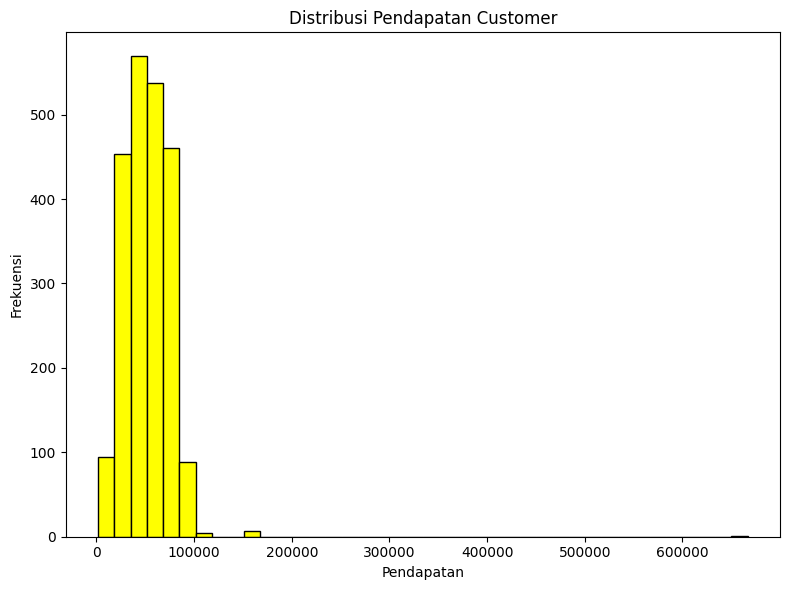

In [57]:
plt.figure(figsize=(8, 6))

plt.hist(df["Income"], bins=40, color="yellow", edgecolor="black")

plt.title("Distribusi Pendapatan Customer")
plt.xlabel("Pendapatan")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.savefig("viz3_histogram_Income.png")
plt.show()


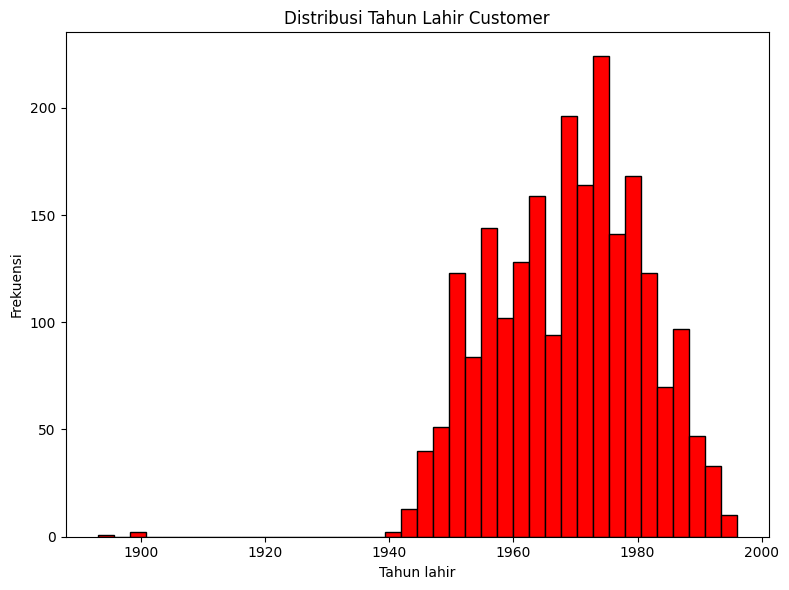

In [58]:
plt.figure(figsize=(8, 6))

plt.hist(df["Year_Birth"], bins=40, color="red", edgecolor="black")

plt.title("Distribusi Tahun Lahir Customer")
plt.xlabel("Tahun lahir")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.savefig("viz3_histogram_Age.png")
plt.show()

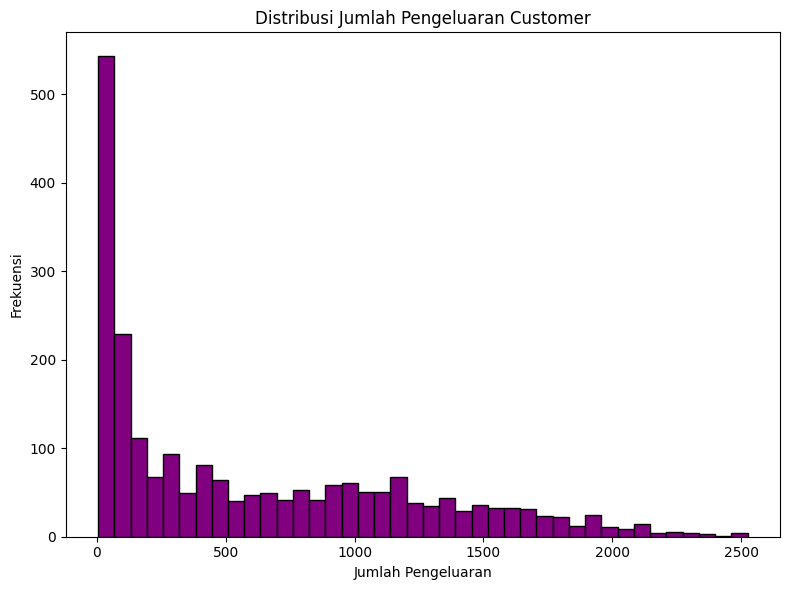

In [59]:
plt.figure(figsize=(8, 6))

plt.hist(df["Total_Spent"], bins=40, color="purple", edgecolor="black")

plt.title("Distribusi Jumlah Pengeluaran Customer")
plt.xlabel("Jumlah Pengeluaran")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.savefig("viz3_histogram_Total_spent.png")
plt.show()

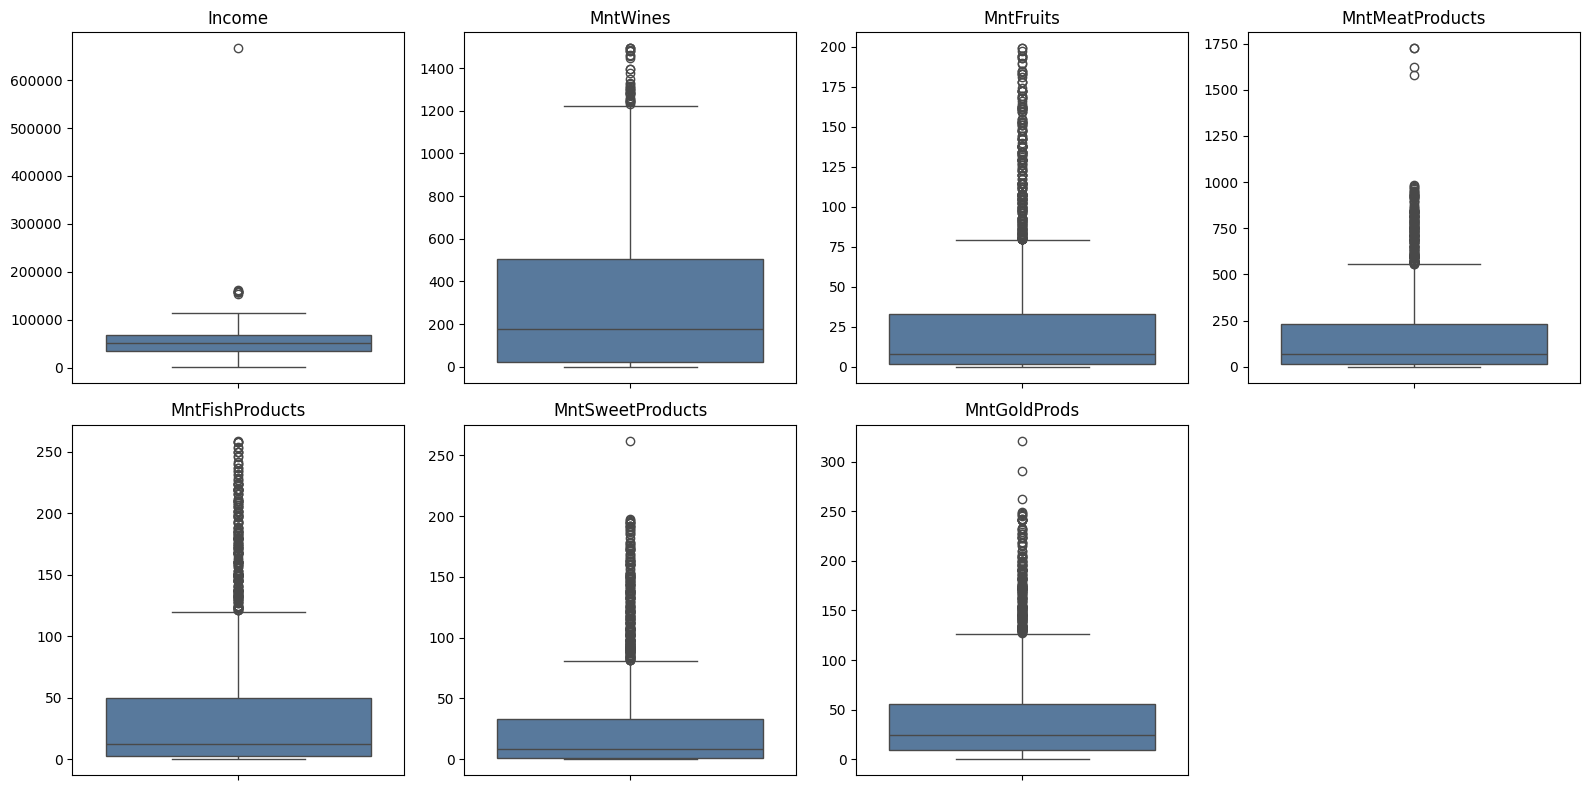

In [60]:
cols = ['Income', 'MntWines', 'MntFruits', 'MntMeatProducts',
        'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax, color='#4C78A8')
    ax.set_title(col)
    ax.set_ylabel('')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

In [61]:
def hitung_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < batas_bawah) | (s > batas_atas)).sum()

ringkasan = pd.DataFrame({
    'jumlah_outlier': {c: hitung_outlier(df[c]) for c in cols},
})
ringkasan['persen'] = (ringkasan['jumlah_outlier'] / len(df) * 100).round(1)
print(ringkasan)

                  jumlah_outlier  persen
Income                         8     0.4
MntWines                      35     1.6
MntFruits                    246    11.1
MntMeatProducts              174     7.9
MntFishProducts              222    10.0
MntSweetProducts             246    11.1
MntGoldProds                 205     9.3


In [62]:
df = df[df['Income'] < 600000]
df = df[df['Age'] <= 100]
df = df[~df['Marital_Status'].isin(['Absurd', 'YOLO'])]


df['Marital_Status'] = df['Marital_Status'].replace({'Alone': 'Single'})

print(df.shape)

(2208, 32)


In [63]:
kolom = ["Income", "MntWines", "MntFruits", "MntMeatProducts",
         "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

df_clean = df.copy()

df_clean = df_clean[df_clean["Income"] < 200000]
df_clean = df_clean[df_clean["MntMeatProducts"] < 1500]
df_clean = df_clean[~((df_clean["NumWebVisitsMonth"] <= 1) &
                      (df_clean["NumWebPurchases"] > 20))]

print("Sebelum:", len(df), "| Sesudah:", len(df_clean))


df_win = df_clean.copy()

for k in kolom:
    batas_atas = df_win[k].quantile(0.99)
    df_win[k] = df_win[k].clip(upper=batas_atas)

Sebelum: 2208 | Sesudah: 2201


In [64]:
df_win = df_clean.copy()

for k in kolom:
    batas_atas = df_win[k].quantile(0.99)
    df_win[k] = df_win[k].clip(upper=batas_atas)

df_log = df_clean.copy()
for k in kolom:
    df_log[k + "_log"] = np.log1p(df_log[k])

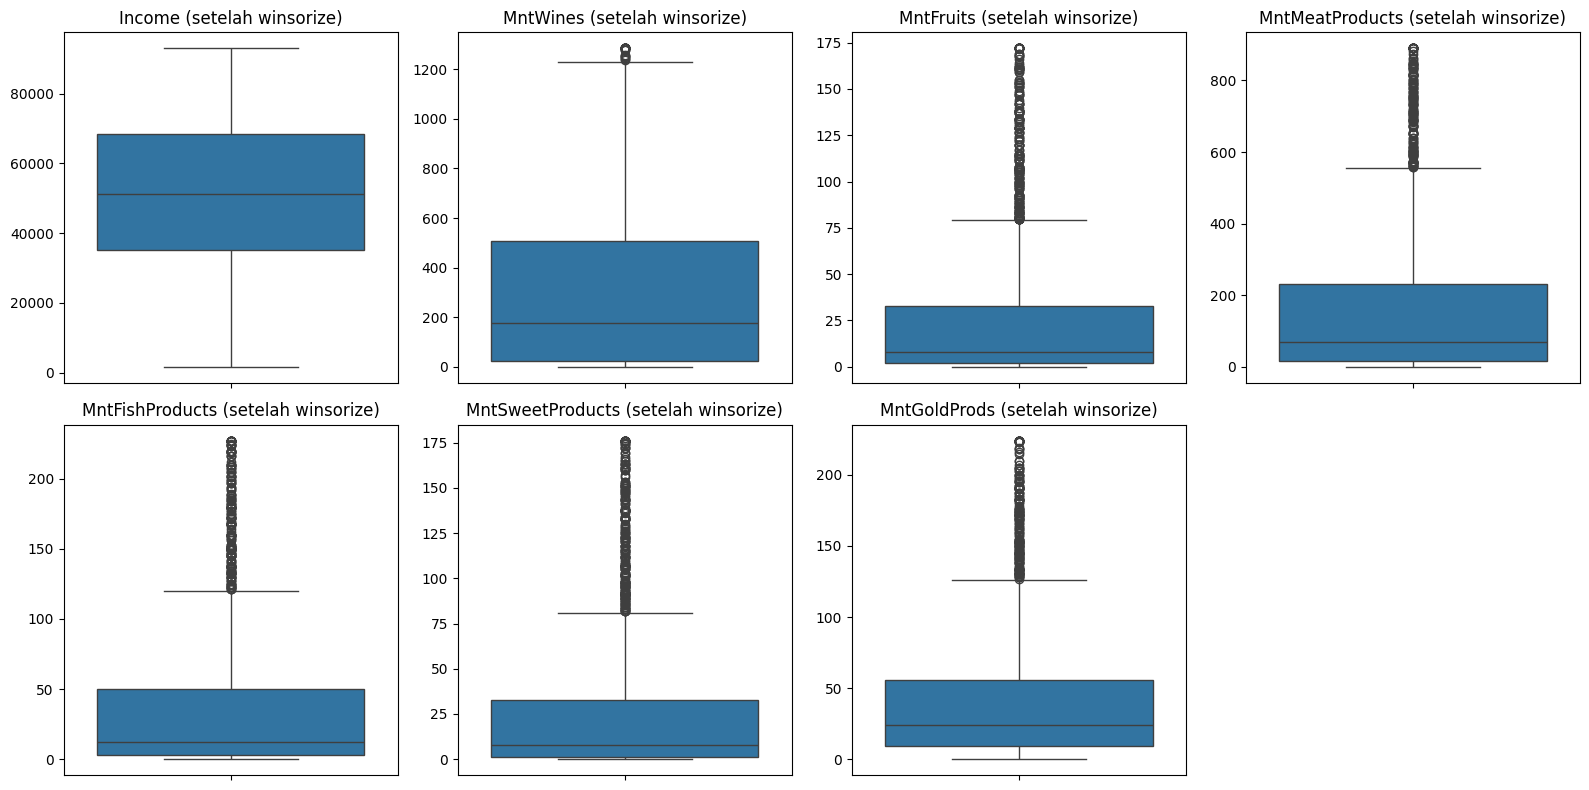

In [65]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, k in zip(axes.flatten(), kolom):
    sns.boxplot(y=df_win[k], ax=ax)
    ax.set_title(k + " (setelah winsorize)")
    ax.set_ylabel("")
axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

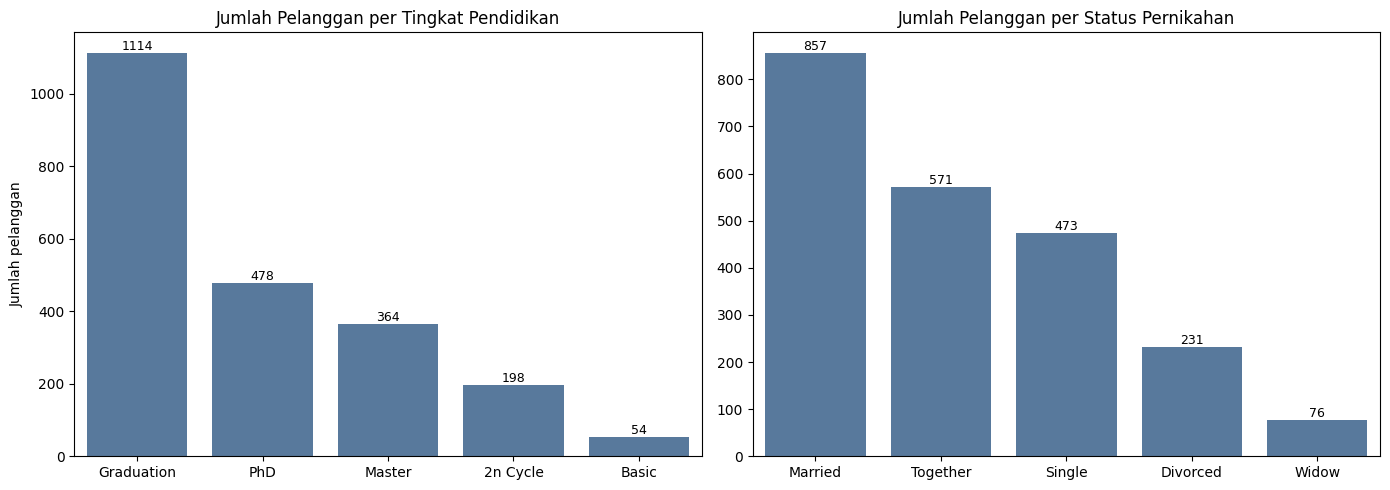

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.countplot(data=df, x='Education', ax=axes[0],
              order=df['Education'].value_counts().index, color='#4C78A8')
axes[0].set_title('Jumlah Pelanggan per Tingkat Pendidikan')
axes[0].set_xlabel('')
axes[0].set_ylabel('Jumlah pelanggan')


sns.countplot(data=df, x='Marital_Status', ax=axes[1],
              order=df['Marital_Status'].value_counts().index, color='#4C78A8')
axes[1].set_title('Jumlah Pelanggan per Status Pernikahan')
axes[1].set_xlabel('')
axes[1].set_ylabel('')


for ax in axes:
    for bar in ax.patches:
        ax.annotate(int(bar.get_height()),
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

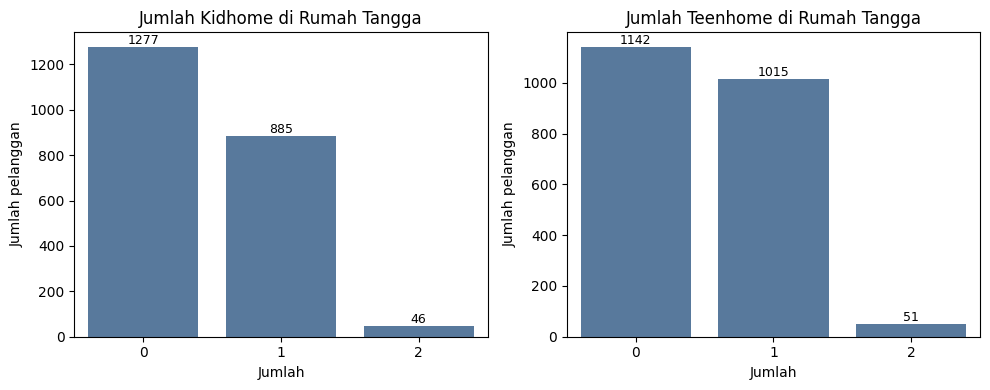

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ['Kidhome', 'Teenhome']):
    sns.countplot(data=df, x=col, ax=ax, color='#4C78A8')
    ax.set_title(f'Jumlah {col} di Rumah Tangga')
    ax.set_xlabel('Jumlah')
    ax.set_ylabel('Jumlah pelanggan')
    for bar in ax.patches:
        ax.annotate(int(bar.get_height()),
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()

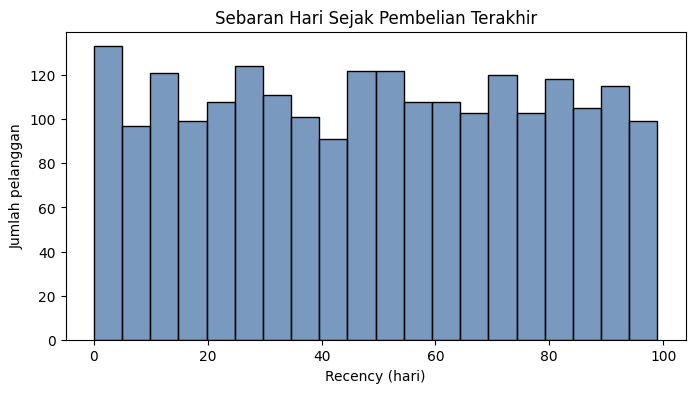

In [68]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='Recency', bins=20, color='#4C78A8')
plt.title('Sebaran Hari Sejak Pembelian Terakhir')
plt.xlabel('Recency (hari)')
plt.ylabel('Jumlah pelanggan')
plt.show()

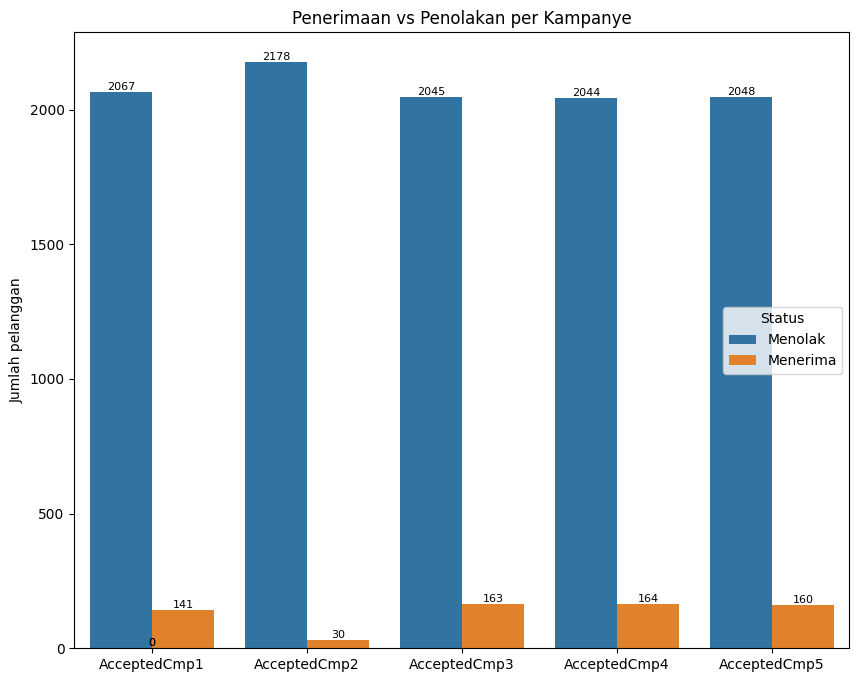

In [69]:
cmp_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
            'AcceptedCmp4', 'AcceptedCmp5']

long = df[cmp_cols].melt(var_name='Kampanye', value_name='Nilai')
long['Status'] = long['Nilai'].map({1: 'Menerima', 0: 'Menolak'})

plt.figure(figsize=(10, 8))
ax = sns.countplot(data=long, x='Kampanye', hue='Status',
                   order=cmp_cols, hue_order=['Menolak', 'Menerima'])
ax.set_title('Penerimaan vs Penolakan per Kampanye')
ax.set_xlabel('')
ax.set_ylabel('Jumlah pelanggan')
for bar in ax.patches:
    ax.annotate(int(bar.get_height()),
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom', fontsize=8)
plt.show()

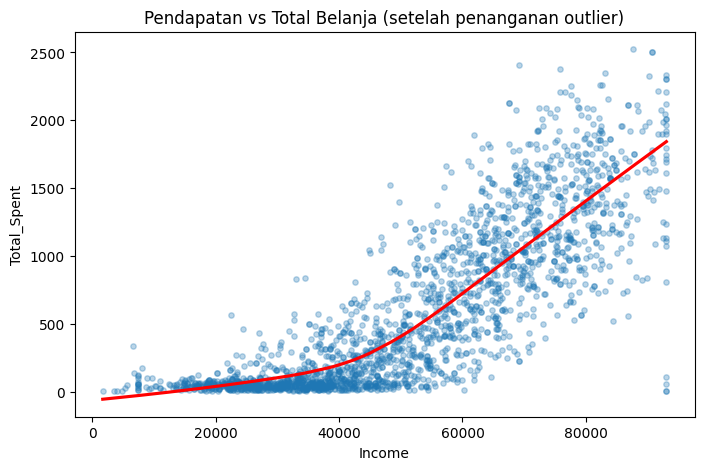

               Income  Total_Spent
Income       1.000000     0.856496
Total_Spent  0.856496     1.000000


In [70]:
df_win["Total_Spent"] = df_win[["MntWines", "MntFruits", "MntMeatProducts",
                                "MntFishProducts", "MntSweetProducts",
                                "MntGoldProds"]].sum(axis=1)

plt.figure(figsize=(8, 5))
sns.regplot(data=df_win, x="Income", y="Total_Spent", lowess=True,
            scatter_kws={"alpha": 0.3, "s": 15}, line_kws={"color": "red"})
plt.title("Pendapatan vs Total Belanja (setelah penanganan outlier)")
plt.show()

print(df_win[["Income", "Total_Spent"]].corr(method="spearman"))

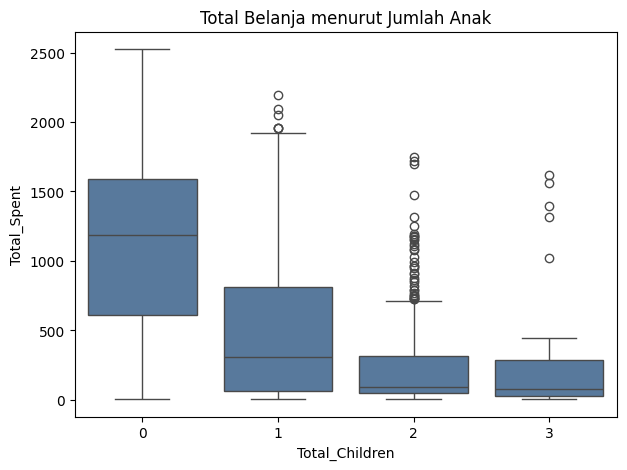

In [71]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Total_Children', y='Total_Spent', color=biru)
plt.title('Total Belanja menurut Jumlah Anak')
plt.show()



### **Interpretasi Boxplot: Total Belanja vs Jumlah Anak (`Total_Spent` vs `Total_Children`)**

Berdasarkan boxplot di atas, kita dapat mengidentifikasi hubungan yang sangat jelas dan menarik antara jumlah anak yang tinggal di rumah tangga pelanggan dengan total belanja mereka:

1. **Korelasi Negatif yang Kuat**:
   * Terdapat penurunan drastis pada pengeluaran rata-rata (*median*) seiring bertambahnya jumlah anak di rumah tangga.
   * **Tanpa Anak (0)**: Memiliki median total belanja tertinggi (mendekati **$1.000** atau lebih), dengan rentang sebaran yang sangat luas hingga mencapai batas atas maksimum hampir **$2.500**.
   * **1 Anak**: Median total belanja turun secara signifikan menjadi sekitar **$400**.
   * **2 atau 3 Anak**: Median pengeluaran turun lebih jauh lagi hingga di bawah **$100-200**.

2. **Penyebaran Data (*Interquartile Range - IQR*)**:
   * Rumah tangga tanpa anak menunjukkan variabilitas belanja yang sangat tinggi (kotak biru yang sangat panjang). Ini berarti ada kelompok pelanggan tanpa anak yang sangat hemat, namun ada juga yang merupakan pembelanja kelas berat (*heavy spenders*).
   * Sebaliknya, rumah tangga dengan 2 atau 3 anak memiliki sebaran yang sangat sempit dan mengumpul di bagian bawah. Pola belanja mereka jauh lebih seragam dan cenderung hemat.

3. **Analisis Aspek Bisnis & Perilaku Konsumen**:
   * **Disposable Income**: Rumah tangga tanpa anak umumnya memiliki sisa pendapatan siap pakai (*disposable income*) yang lebih besar karena tidak memiliki biaya tanggungan untuk kebutuhan anak. Mereka memiliki kebebasan finansial untuk membelanjakan uang pada produk non-primer seperti wine premium atau daging berkualitas tinggi.
   * **Prioritas Keuangan**: Kehadiran anak (terutama $\ge 2$) mengalihkan fokus anggaran rumah tangga ke arah biaya pendidikan, tabungan, dan kebutuhan pokok sehari-hari yang mungkin tidak tercatat penuh di kategori produk retail ini, atau memaksa mereka untuk jauh lebih berhemat.

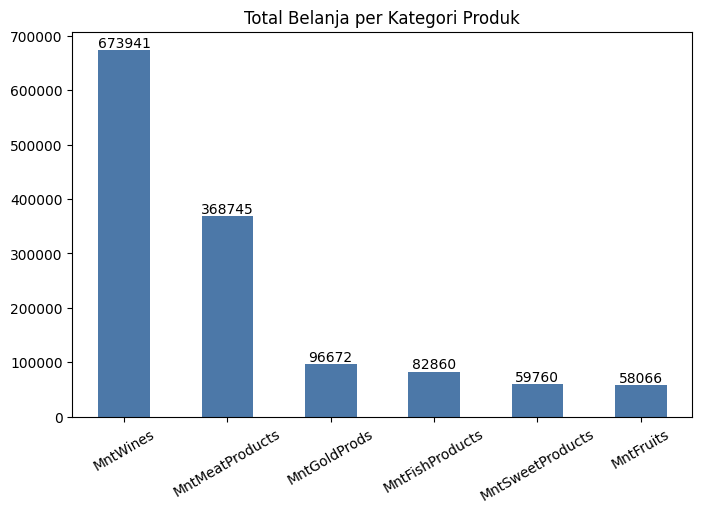

In [72]:
mnt_cols = ['MntWines', 'MntFruits', 'MntMeatProducts',
            'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
total_produk = df[mnt_cols].sum().sort_values(ascending=False)
ax = total_produk.plot(kind='bar', color=biru, figsize=(8, 5))
ax.bar_label(ax.containers[0], fmt='%d')
ax.set_title('Total Belanja per Kategori Produk')
plt.xticks(rotation=30)
plt.show()



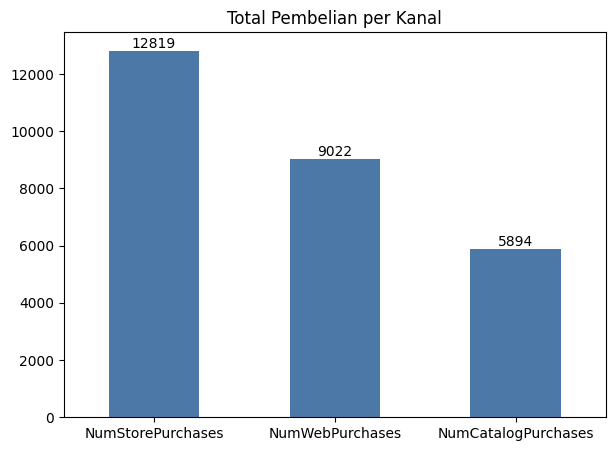

In [73]:
kanal = df[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum()
ax = kanal.sort_values(ascending=False).plot(kind='bar', color=biru, figsize=(7, 5))
ax.bar_label(ax.containers[0], fmt='%d')
ax.set_title('Total Pembelian per Kanal')
plt.xticks(rotation=0)
plt.show()



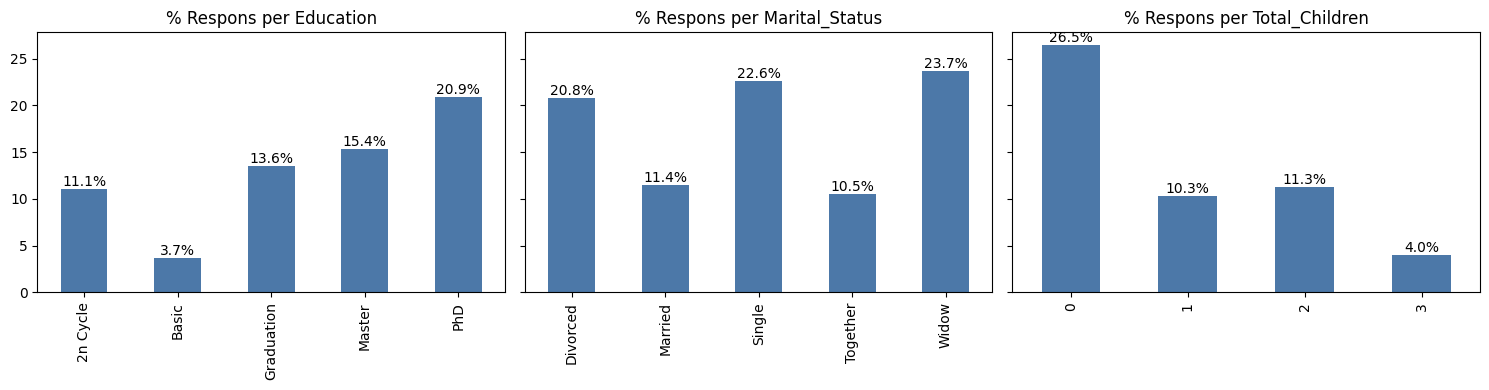

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ['Education', 'Marital_Status', 'Total_Children']):
    rate = df.groupby(col)['Response'].mean() * 100
    rate.plot(kind='bar', ax=ax, color=biru)
    ax.bar_label(ax.containers[0], fmt='%.1f%%')
    ax.set_title(f'% Respons per {col}')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()



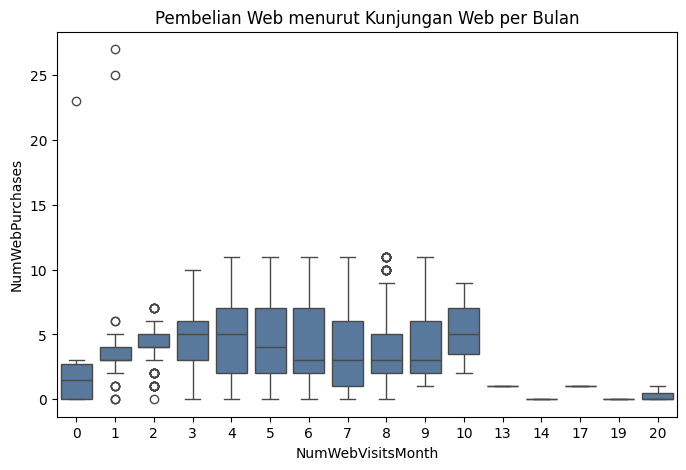

In [75]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='NumWebVisitsMonth', y='NumWebPurchases', color=biru)
plt.title('Pembelian Web menurut Kunjungan Web per Bulan')
plt.show()

In [76]:

print(df[df["NumWebPurchases"] > 20][["NumWebPurchases", "NumCatalogPurchases",
                                      "NumStorePurchases", "NumWebVisitsMonth", "Income"]])
print(df["NumWebVisitsMonth"].value_counts().sort_index())


df_clean = df[df["NumWebPurchases"] <= 20].copy()
print("Sebelum:", len(df), "| Sesudah:", len(df_clean))


df_clean["Kunjungan_Web"] = df_clean["NumWebVisitsMonth"].astype(str)
df_clean.loc[df_clean["NumWebVisitsMonth"] >= 11, "Kunjungan_Web"] = "11+"
urutan = [str(i) for i in range(0, 11)] + ["11+"]


      NumWebPurchases  NumCatalogPurchases  NumStorePurchases  \
1789               23                    1                  1   
1881               27                    0                  0   
1958               25                    0                  0   

      NumWebVisitsMonth    Income  
1789                  0    7144.0  
1881                  1  113734.0  
1958                  1    4428.0  
NumWebVisitsMonth
0      10
1     148
2     200
3     203
4     216
5     278
6     334
7     387
8     338
9      82
10      3
13      1
14      2
17      1
19      2
20      3
Name: count, dtype: int64
Sebelum: 2208 | Sesudah: 2205


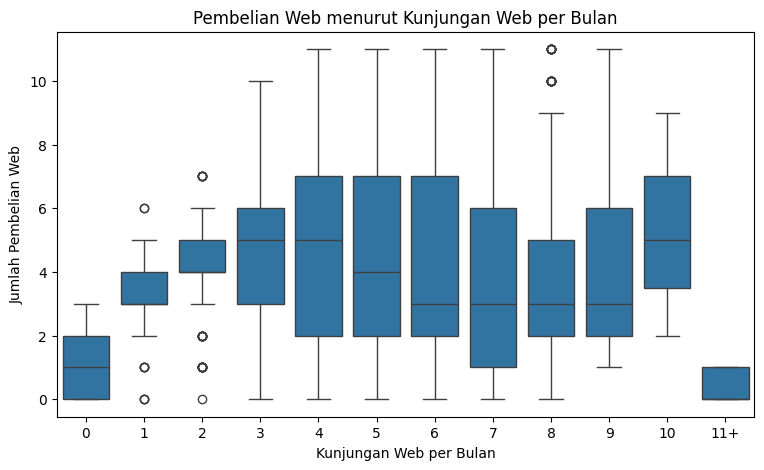

In [77]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x="Kunjungan_Web", y="NumWebPurchases", order=urutan)
plt.title("Pembelian Web menurut Kunjungan Web per Bulan")
plt.xlabel("Kunjungan Web per Bulan")
plt.ylabel("Jumlah Pembelian Web")
plt.show()



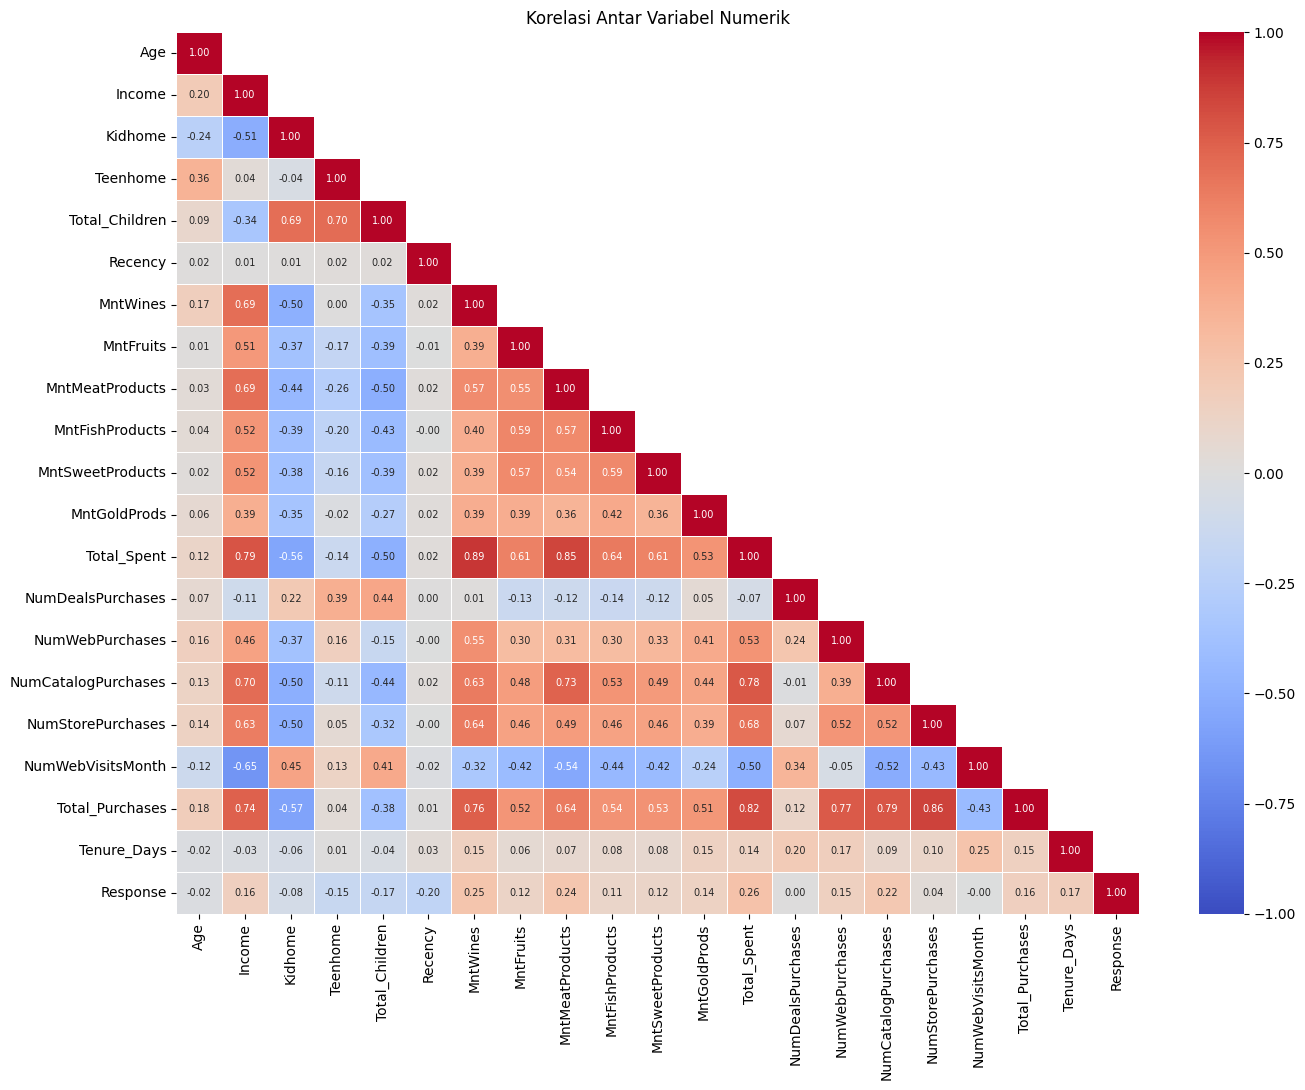

In [78]:
kolom = ['Age', 'Income', 'Kidhome', 'Teenhome', 'Total_Children', 'Recency',
         'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
         'MntSweetProducts', 'MntGoldProds', 'Total_Spent',
         'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
         'NumStorePurchases', 'NumWebVisitsMonth', 'Total_Purchases',
         'Tenure_Days', 'Response']


korelasi = df[kolom].corr()

mask = np.triu(np.ones_like(korelasi, dtype=bool), k=1)

plt.figure(figsize=(14, 11))
sns.heatmap(korelasi, mask=mask, cmap='coolwarm', center=0,
            vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7}, linewidths=0.5)
plt.title('Korelasi Antar Variabel Numerik')
plt.tight_layout()
plt.show()

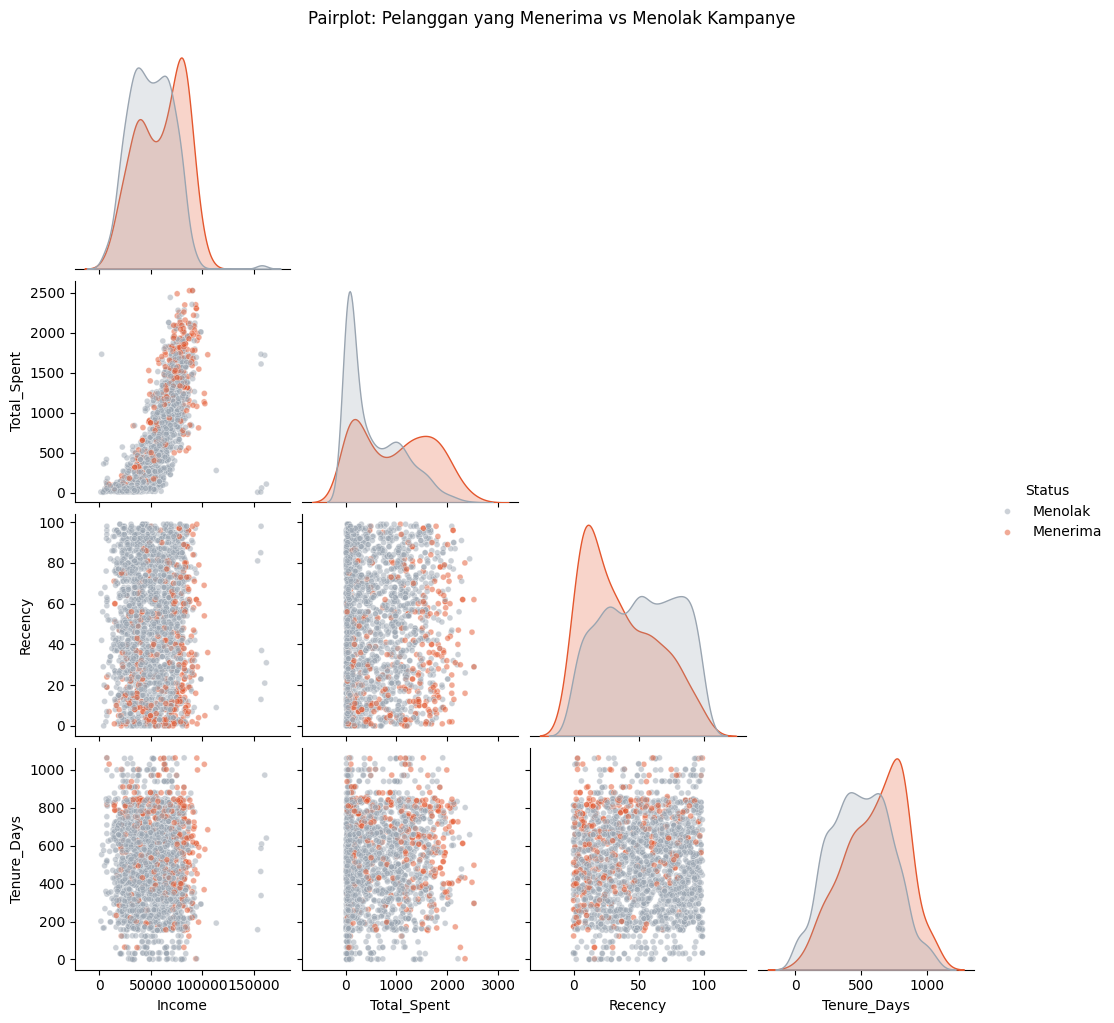

In [79]:
df['Status'] = df['Response'].map({0: 'Menolak', 1: 'Menerima'})

kolom_pair = ['Income', 'Total_Spent', 'Recency', 'Tenure_Days']

g = sns.pairplot(
    df,
    vars=kolom_pair,
    hue='Status',
    hue_order=['Menolak', 'Menerima'],
    palette={'Menolak': '#9AA5B1', 'Menerima': '#E4572E'},
    diag_kind='kde',
    corner=True,
    plot_kws={'alpha': 0.5, 's': 18},
    diag_kws={'common_norm': False},
)
g.figure.suptitle('Pairplot: Pelanggan yang Menerima vs Menolak Kampanye', y=1.02)
plt.show()

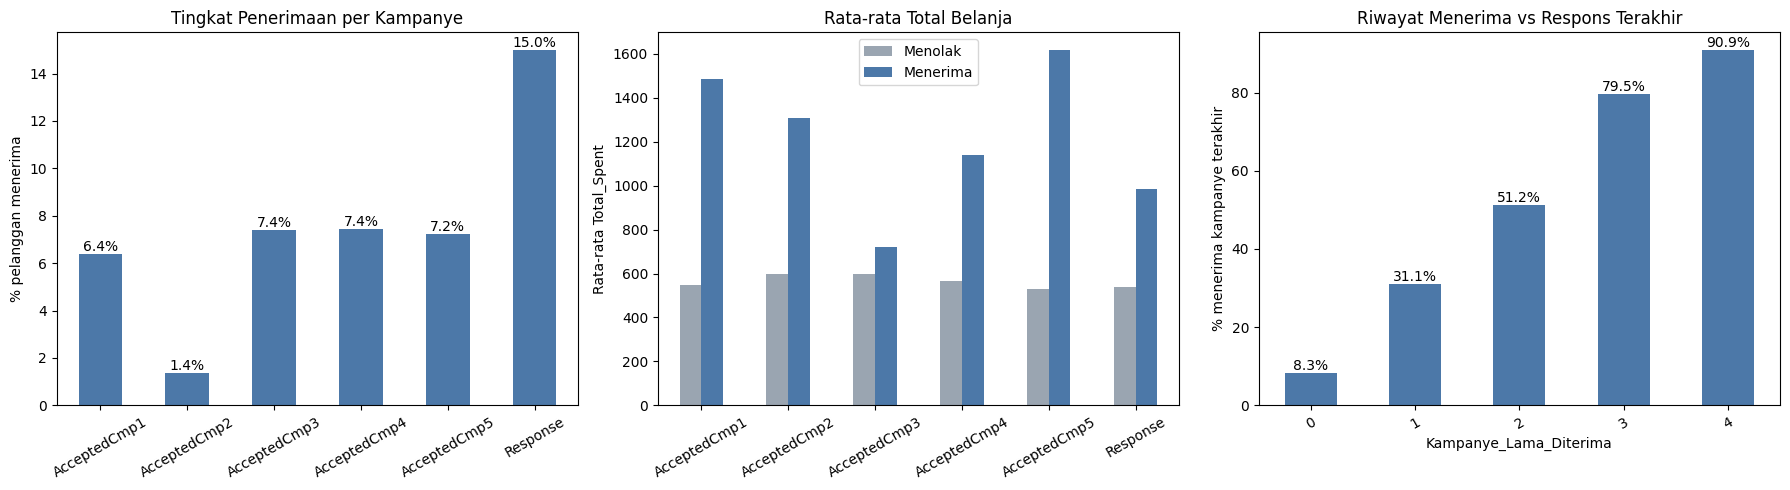

In [80]:
cmp_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
            'AcceptedCmp4', 'AcceptedCmp5', 'Response']
biru, abu = '#4C78A8', '#9AA5B1'

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: tingkat penerimaan per kampanye
rate = df[cmp_cols].mean() * 100
rate.plot(kind='bar', ax=axes[0], color=biru)
axes[0].bar_label(axes[0].containers[0], fmt='%.1f%%')
axes[0].set_title('Tingkat Penerimaan per Kampanye')
axes[0].set_ylabel('% pelanggan menerima')

# Chart 2: rata-rata Total_Spent, menerima vs menolak
spent = pd.DataFrame({c: df.groupby(c)['Total_Spent'].mean() for c in cmp_cols}).T
spent.columns = ['Menolak', 'Menerima']
spent.plot(kind='bar', ax=axes[1], color=[abu, biru])
axes[1].set_title('Rata-rata Total Belanja')
axes[1].set_ylabel('Rata-rata Total_Spent')

# Chart 3: pernah menerima kampanye lama -> % menerima kampanye terakhir
df['Kampanye_Lama_Diterima'] = df[cmp_cols[:5]].sum(axis=1)
r = df.groupby('Kampanye_Lama_Diterima')['Response'].mean() * 100
r.plot(kind='bar', ax=axes[2], color=biru)
axes[2].bar_label(axes[2].containers[0], fmt='%.1f%%')
axes[2].set_title('Riwayat Menerima vs Respons Terakhir')
axes[2].set_ylabel('% menerima kampanye terakhir')

for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

# EDA Classification


Cek Missing Values
ID                        0
Year_Birth                0
Education                 0
Marital_Status            0
Income                    0
Kidhome                   0
Teenhome                  0
Dt_Customer               0
Recency                   0
MntWines                  0
MntFruits                 0
MntMeatProducts           0
MntFishProducts           0
MntSweetProducts          0
MntGoldProds              0
NumDealsPurchases         0
NumWebPurchases           0
NumCatalogPurchases       0
NumStorePurchases         0
NumWebVisitsMonth         0
AcceptedCmp3              0
AcceptedCmp4              0
AcceptedCmp5              0
AcceptedCmp1              0
AcceptedCmp2              0
Response                  0
Age                       0
Tenure_Days               0
Total_Spent               0
Total_Children            0
Total_Purchases           0
Total_Accepted            0
Status                    0
Kampanye_Lama_Diterima    0
dtype: int64

Total missing 

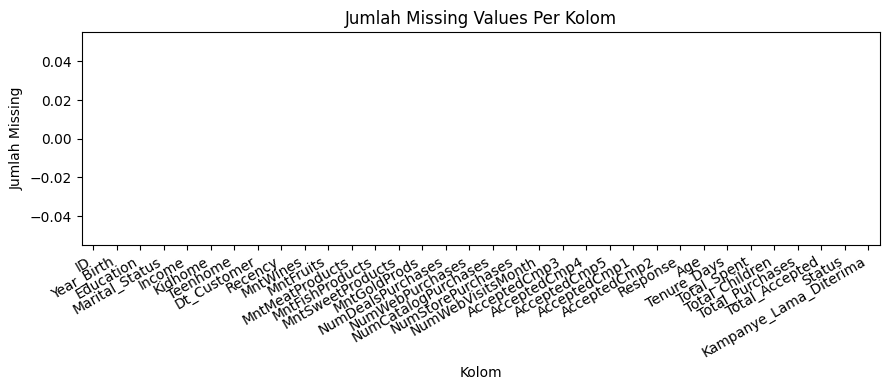

In [81]:
print("\n" + "=" * 50)
print("Cek Missing Values")
print("=" * 50)

missing = df.isnull().sum()
print(missing)
print(f"\nTotal missing values: {missing.sum()}")

plt.figure(figsize=(9, 4))
missing.plot(kind="bar", color="tomato", edgecolor="white")
plt.title("Jumlah Missing Values Per Kolom")
plt.xlabel("Kolom")
plt.ylabel("Jumlah Missing")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("step1_missing_values.png")
plt.show()

In [82]:
print("\n" + "=" * 50)
print("Cek Duplikat")
print("=" * 50)

jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    df = df.drop_duplicates()
    print(f"Duplikat berhasil dihapus. Sisa baris: {len(df)}")
else:
    print("Tidak ada duplikat. Data tetap.")


Cek Duplikat
Jumlah baris duplikat: 0
Tidak ada duplikat. Data tetap.


In [83]:
kolom_numerik = df.select_dtypes(include='number').columns.tolist()

for kolom in ['ID', 'Year_Birth', 'Kidhome', 'Teenhome']:
    if kolom in kolom_numerik:
        kolom_numerik.remove(kolom)

print(kolom_numerik)
print(len(kolom_numerik), 'kolom numerik')


['Income', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response', 'Age', 'Tenure_Days', 'Total_Spent', 'Total_Children', 'Total_Purchases', 'Total_Accepted', 'Kampanye_Lama_Diterima']
26 kolom numerik



LANGKAH 3 - Deteksi Outlier (Metode IQR)
Income          : 7 outlier  (batas: -14740.50 - 118423.50)
Recency         : 0 outlier  (batas: -51.00 - 149.00)
MntWines        : 35 outlier  (batas: -698.25 - 1227.75)
MntFruits       : 244 outlier  (batas: -45.12 - 79.88)
MntMeatProducts : 173 outlier  (batas: -308.38 - 556.62)
MntFishProducts : 220 outlier  (batas: -67.50 - 120.50)
MntSweetProducts : 246 outlier  (batas: -47.00 - 81.00)
MntGoldProds    : 202 outlier  (batas: -61.50 - 126.50)
NumDealsPurchases : 84 outlier  (batas: -2.00 - 6.00)
NumWebPurchases : 3 outlier  (batas: -4.00 - 12.00)
NumCatalogPurchases : 23 outlier  (batas: -6.00 - 10.00)
NumStorePurchases : 0 outlier  (batas: -4.50 - 15.50)
NumWebVisitsMonth : 8 outlier  (batas: -3.00 - 13.00)
AcceptedCmp3    : 163 outlier  (batas: 0.00 - 0.00)
AcceptedCmp4    : 164 outlier  (batas: 0.00 - 0.00)
AcceptedCmp5    : 160 outlier  (batas: 0.00 - 0.00)
AcceptedCmp1    : 141 outlier  (batas: 0.00 - 0.00)
AcceptedCmp2    : 30 outlier

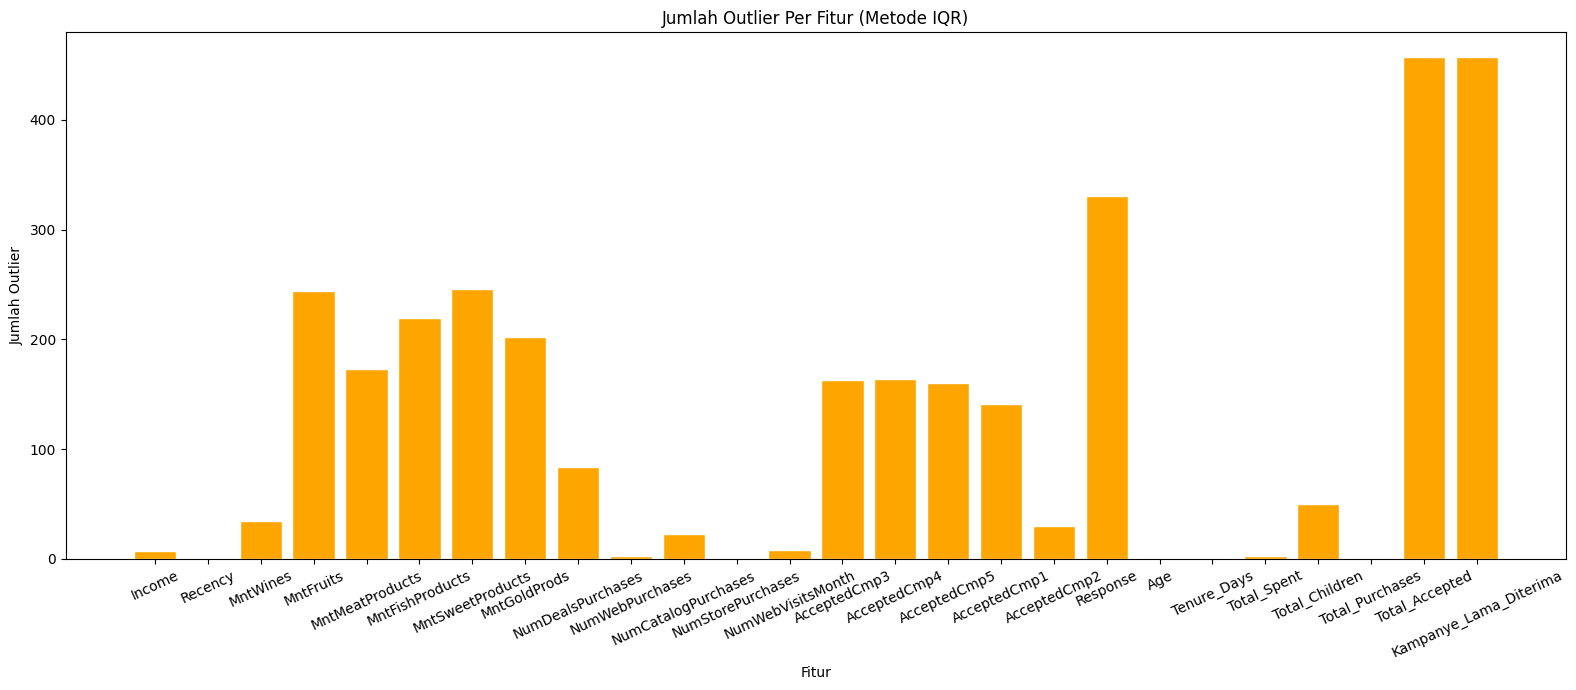

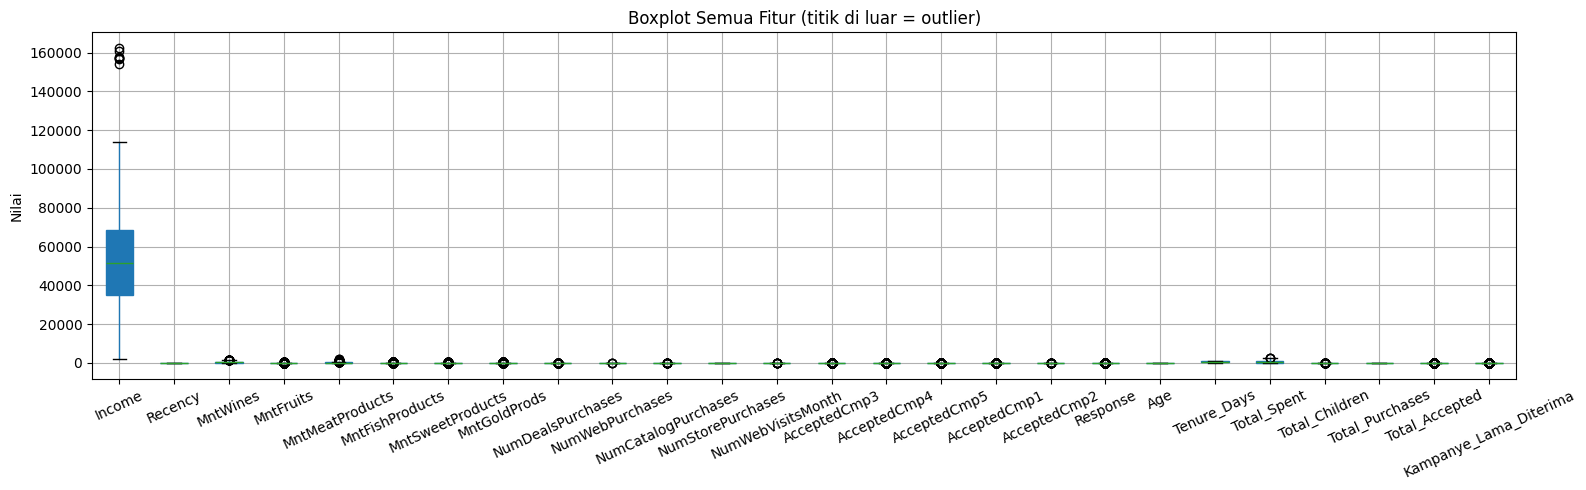

In [84]:
print("\n" + "=" * 50)
print("LANGKAH 3 - Deteksi Outlier (Metode IQR)")
print("=" * 50)

jumlah_outlier = {}

for kolom in kolom_numerik:
    Q1  = df[kolom].quantile(0.25)   # kuartil bawah
    Q3  = df[kolom].quantile(0.75)   # kuartil atas
    IQR = Q3 - Q1                    # rentang antar kuartil

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas  = Q3 + 1.5 * IQR

    outlier = df[(df[kolom] < batas_bawah) | (df[kolom] > batas_atas)]
    jumlah_outlier[kolom] = len(outlier)
    print(f"{kolom:15s} : {len(outlier)} outlier  "
          f"(batas: {batas_bawah:.2f} - {batas_atas:.2f})")

# Visualisasi jumlah outlier
plt.figure(figsize=(16, 7))
plt.bar(jumlah_outlier.keys(), jumlah_outlier.values(),
        color="orange", edgecolor="white")
plt.title("Jumlah Outlier Per Fitur (Metode IQR)")
plt.xlabel("Fitur")
plt.ylabel("Jumlah Outlier")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("step3_outlier.png")
plt.show()

# Visualisasi boxplot untuk melihat sebaran outlier
plt.figure(figsize=(16, 5))
df[kolom_numerik].boxplot(patch_artist=True)
plt.title("Boxplot Semua Fitur (titik di luar = outlier)")
plt.ylabel("Nilai")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("step3_boxplot_outlier.png")
plt.show()


### **Interpretasi Visualisasi: Deteksi Outlier Menggunakan Metode IQR**

Berdasarkan hasil eksekusi dan grafik batang **"Jumlah Outlier Per Fitur (Metode IQR)"** di atas, kita dapat merangkum karakteristik sebaran data ekstrem (*outlier*) sebagai berikut:

#### **1. Fitur dengan Tingkat Outlier Sangat Tinggi (Kolom Belanja Produk)**
* **`MntSweetProducts` (223 outlier), `MntFruits` (220 outlier), dan `MntFishProducts` (200 outlier)**:
  * Lebih dari **10%** data pelanggan diidentifikasi sebagai outlier pada kategori buah, manisan, dan ikan.
  * **Insight Bisnis**: Ini menunjukkan adanya kelompok kecil pelanggan spesifik (*niche market*) yang sangat menyukai produk-produk ini dan berbelanja dalam jumlah yang jauh melampaui rata-rata pelanggan umum. Kelompok ini adalah target ideal untuk program promosi loyalitas produk spesifik.

#### **2. Fitur Demografi & Finansial dengan Outlier Sangat Rendah**
* **`Income` (7 outlier) dan `Age` (0 outlier)**:
  * Setelah dilakukan pembersihan data awal (menghapus pendapatan abnormal dan usia di atas 100 tahun), kedua pendorong utama demografi ini memiliki distribusi yang sangat bersih dan bebas dari anomali ekstrem.
  * Hal ini menjamin bahwa model klasifikasi nantinya tidak akan terdistorsi oleh data demografis yang bias.

#### **3. Outlier Semu pada Variabel Kampanye (`Total_Accepted`, `AcceptedCmp1-5`)**
* **Variabel Kampanye (Tingkat Outlier hingga 425)**:
  * Fitur-fitur ini bernilai biner ($0$ atau $1$) atau diskrit rendah. Karena mayoritas pelanggan menolak kampanye (nilai $0$), maka pelanggan yang menerima kampanye (nilai $1$ atau lebih) dideteksi sebagai "outlier" secara matematis oleh rumus IQR.
  * **Catatan Teknis**: Outlier pada variabel kampanye ini bukan merupakan kesalahan data (*noise*), melainkan representasi kelompok minoritas yang berharga (pelanggan responsif) yang harus dipertahankan untuk kebutuhan pemodelan prediksi.


Statistik Deskriptif
          Income  Recency  MntWines  MntFruits  MntMeatProducts  \
count    2208.00  2208.00   2208.00    2208.00          2208.00   
mean    51943.52    49.06    305.23      26.30           167.00   
std     21536.76    28.94    337.61      39.73           224.32   
min      1730.00     0.00      0.00       0.00             0.00   
25%     35196.00    24.00     24.00       1.75            16.00   
50%     51371.00    49.00    174.00       8.00            68.00   
75%     68487.00    74.00    505.50      33.00           232.25   
max    162397.00    99.00   1493.00     199.00          1725.00   

       MntFishProducts  MntSweetProducts  MntGoldProds  NumDealsPurchases  \
count          2208.00           2208.00       2208.00            2208.00   
mean             37.53             27.07         43.78               2.32   
std              54.58             41.11         51.51               1.92   
min               0.00              0.00          0.00            

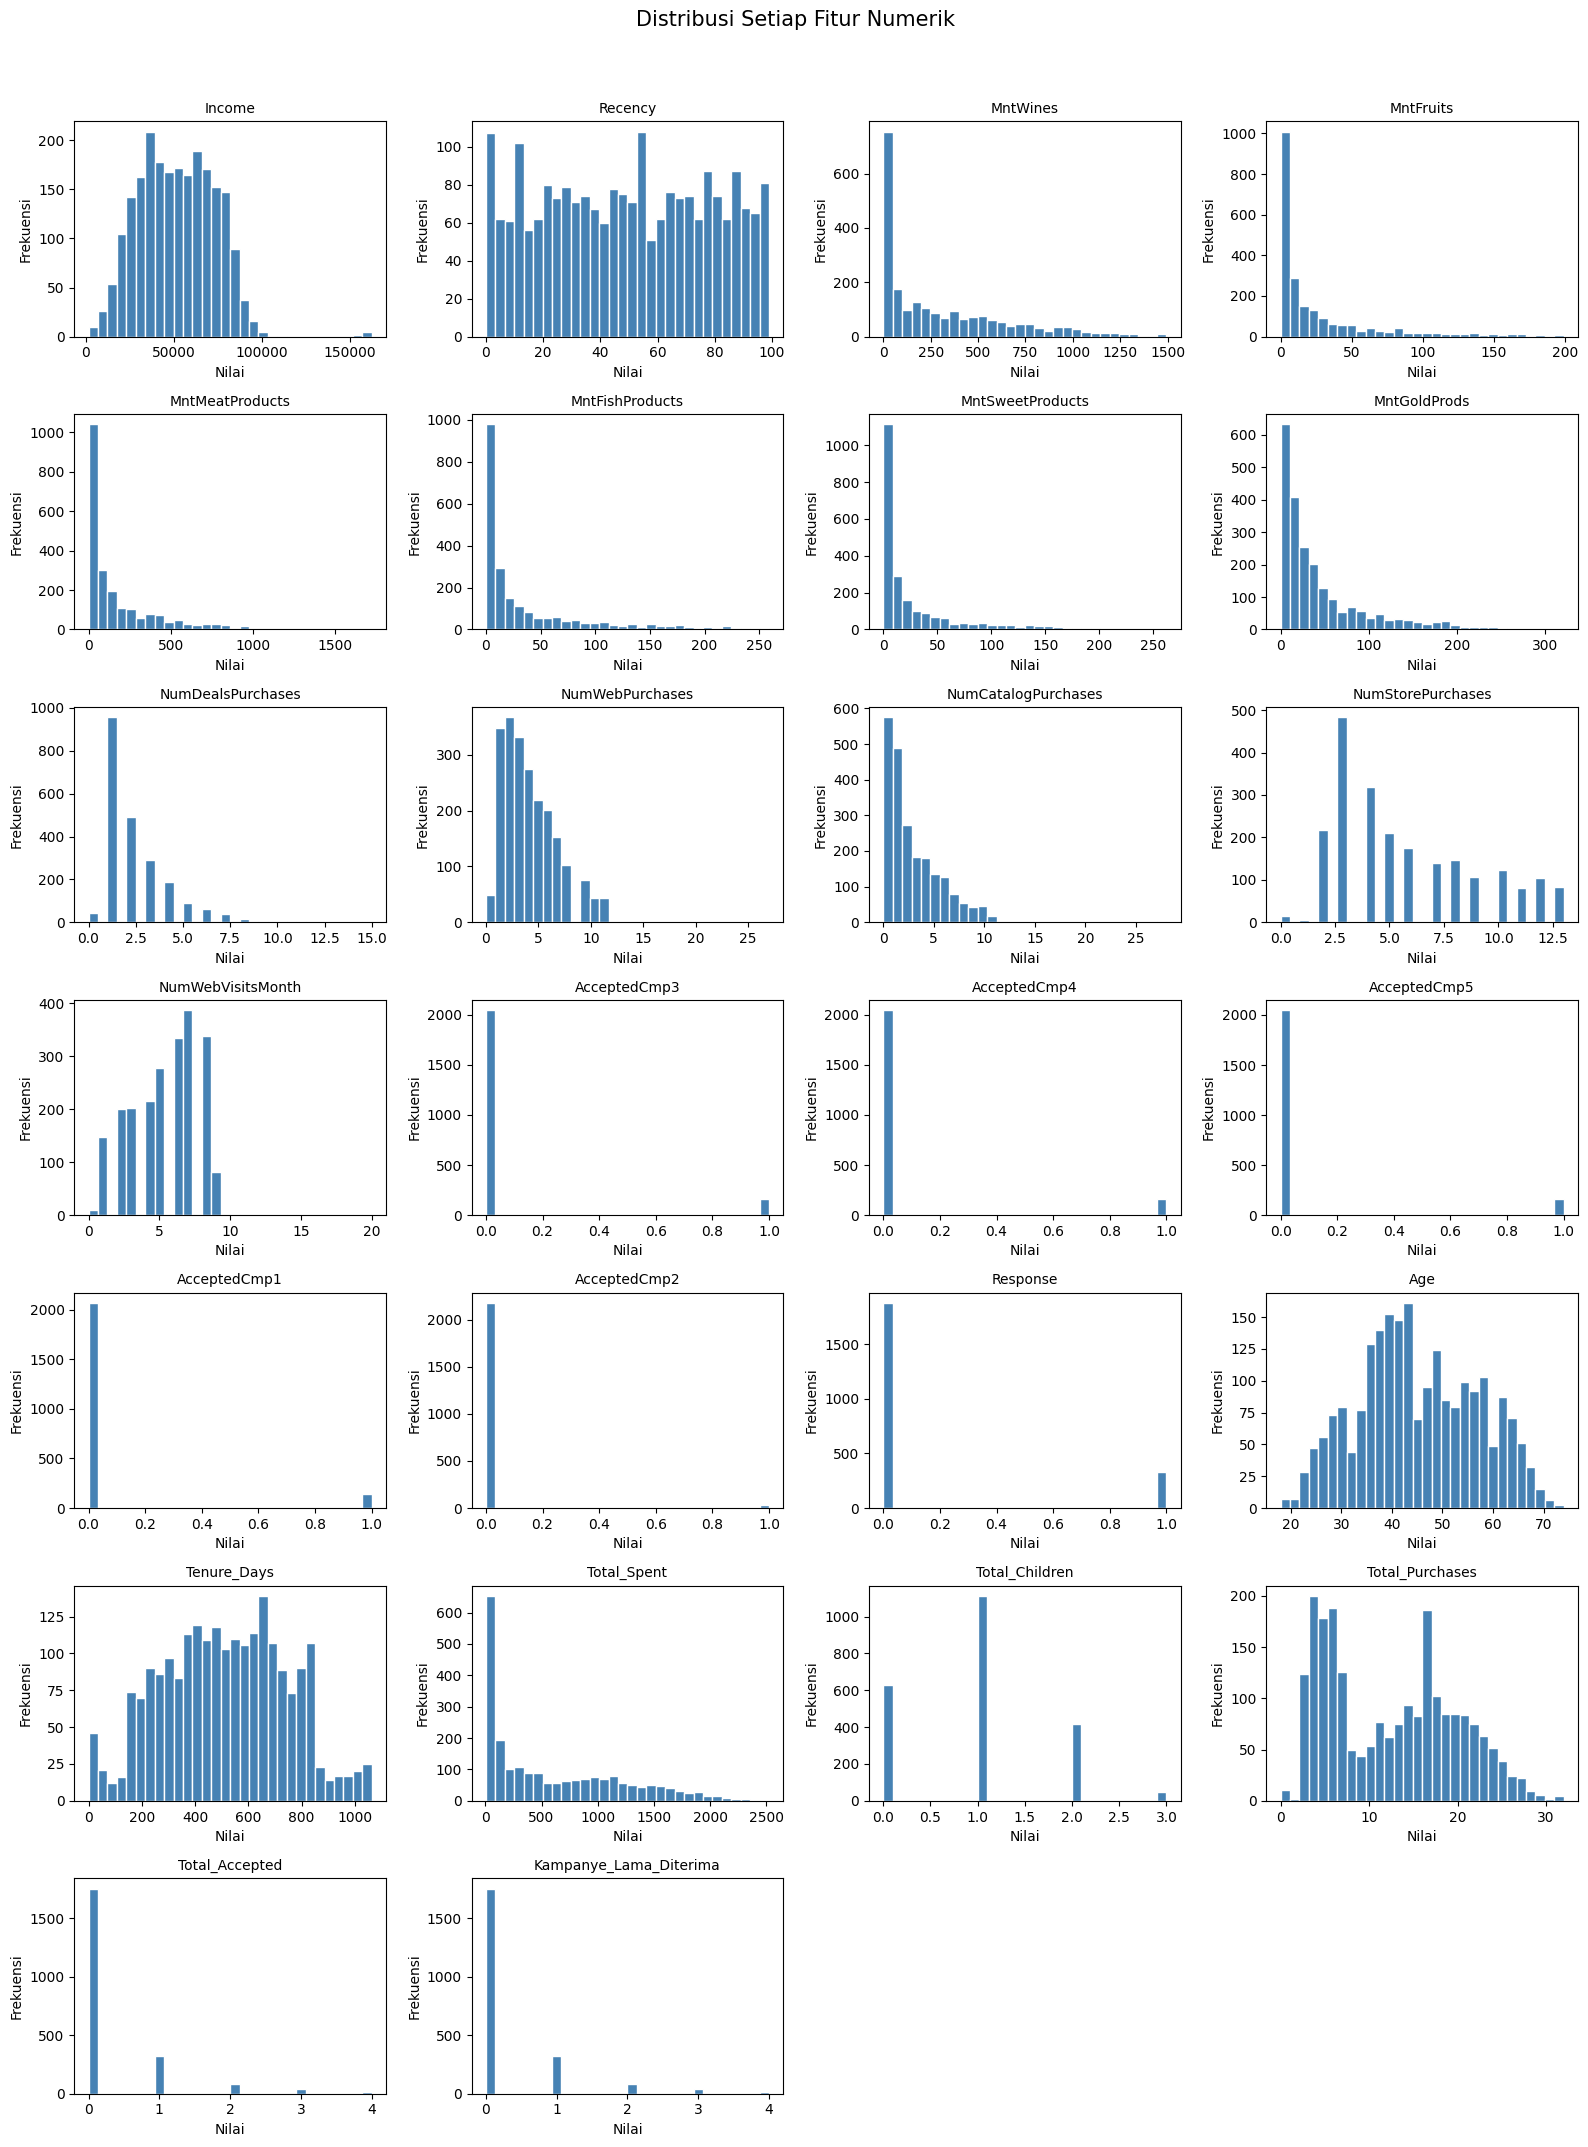

In [85]:
import math

print("\n" + "=" * 50)
print("Statistik Deskriptif")
print("=" * 50)

print(df[kolom_numerik].describe().round(2))

# Menghitung baris dan kolom secara dinamis agar pas untuk semua fitur numerik
n_fitur = len(kolom_numerik)
n_cols = 4
n_rows = math.ceil(n_fitur / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3 * n_rows))
axes = axes.flatten()

for i, kolom in enumerate(kolom_numerik):
    axes[i].hist(df[kolom], bins=30, color="steelblue", edgecolor="white")
    axes[i].set_title(kolom, fontsize=10)
    axes[i].set_xlabel("Nilai")
    axes[i].set_ylabel("Frekuensi")

# Sembunyikan subplot sisa yang kosong
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Distribusi Setiap Fitur Numerik", fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig("step4_distribusi.png", bbox_inches="tight")
plt.show()

In [86]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split

In [87]:
print("\n" + "=" * 50)
print("LANGKAH 5 - Label Encoding (label teks → angka)")
print("=" * 50)

le = LabelEncoder()
df["Education_encoded"] = le.fit_transform(df["Education"])

# Tampilkan hasil mapping
mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print("Mapping label:")
for Lulusan, angka in mapping.items():
    print(f"  {Lulusan:15s} → {angka}")

print()
print(df[["Education", "Education_encoded"]].head(10))


LANGKAH 5 - Label Encoding (label teks → angka)
Mapping label:
  2n Cycle        → 0
  Basic           → 1
  Graduation      → 2
  Master          → 3
  PhD             → 4

    Education  Education_encoded
0  Graduation                  2
1  Graduation                  2
2  Graduation                  2
3  Graduation                  2
4         PhD                  4
5      Master                  3
6  Graduation                  2
7         PhD                  4
8         PhD                  4
9         PhD                  4


In [88]:
print("\n" + "=" * 50)
print("LANGKAH 5 - Label Encoding (label teks → angka)")
print("=" * 50)

le = LabelEncoder()
df["Marital_Status_encoded"] = le.fit_transform(df["Marital_Status"])

# Tampilkan hasil mapping
mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print("Mapping label:")
for Lulusan, angka in mapping.items():
    print(f"  {Lulusan:15s} → {angka}")

print()
print(df[["Marital_Status","Marital_Status_encoded"]].head(10))


LANGKAH 5 - Label Encoding (label teks → angka)
Mapping label:
  Divorced        → 0
  Married         → 1
  Single          → 2
  Together        → 3
  Widow           → 4

  Marital_Status  Marital_Status_encoded
0         Single                       2
1         Single                       2
2       Together                       3
3       Together                       3
4        Married                       1
5       Together                       3
6       Divorced                       0
7        Married                       1
8       Together                       3
9       Together                       3



LANGKAH 6 - Normalisasi (MinMaxScaler: 0 sampai 1)
Sebelum normalisasi:
    Income  Recency  MntWines  MntFruits  MntMeatProducts  MntFishProducts  \
0  58138.0       58       635         88              546              172   
1  46344.0       38        11          1                6                2   
2  71613.0       26       426         49              127              111   

   MntSweetProducts  MntGoldProds  NumDealsPurchases  NumWebPurchases  ...  \
0                88            88                  3                8  ...   
1                 1             6                  2                1  ...   
2                21            42                  1                8  ...   

   AcceptedCmp1  AcceptedCmp2  Response  Age  Tenure_Days  Total_Spent  \
0             0             0         1   57          971         1617   
1             0             0         0   60          125           27   
2             0             0         0   49          472          776   

   T

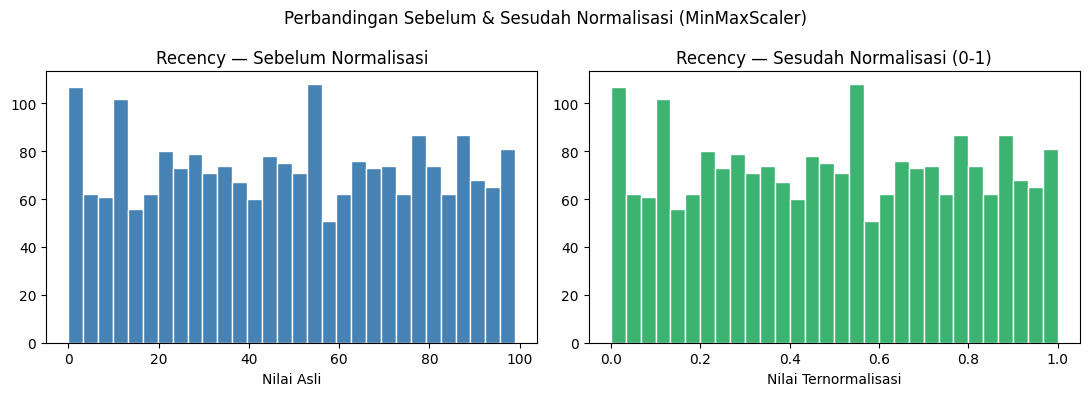

In [89]:
print("\n" + "=" * 50)
print("LANGKAH 6 - Normalisasi (MinMaxScaler: 0 sampai 1)")
print("=" * 50)

scaler_minmax = MinMaxScaler()
df_normalized = df[kolom_numerik].copy()
df_normalized[kolom_numerik] = scaler_minmax.fit_transform(df[kolom_numerik])

print("Sebelum normalisasi:")
print(df[kolom_numerik].head(3).round(3))
print("\nSesudah normalisasi (0-1):")
print(df_normalized.head(3).round(3))

# Visualisasi perbandingan sebelum & sesudah normalisasi (contoh kolom N)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["Recency"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Recency — Sebelum Normalisasi")
axes[0].set_xlabel("Nilai Asli")

axes[1].hist(df_normalized["Recency"], bins=30, color="mediumseagreen", edgecolor="white")
axes[1].set_title("Recency — Sesudah Normalisasi (0-1)")
axes[1].set_xlabel("Nilai Ternormalisasi")

plt.suptitle("Perbandingan Sebelum & Sesudah Normalisasi (MinMaxScaler)")
plt.tight_layout()
plt.savefig("step6_normalisasi.png")
plt.show()


LANGKAH 7 - Standarisasi (StandardScaler: mean=0, std=1)
Sebelum standarisasi:
        Income  Recency  MntWines  MntFruits  MntMeatProducts  \
mean  51943.52    49.06    305.23      26.30           167.00   
std   21536.76    28.94    337.61      39.73           224.32   

      MntFishProducts  MntSweetProducts  MntGoldProds  NumDealsPurchases  \
mean            37.53             27.07         43.78               2.32   
std             54.58             41.11         51.51               1.92   

      NumWebPurchases  ...  AcceptedCmp1  AcceptedCmp2  Response   Age  \
mean             4.09  ...          0.06          0.01      0.15  45.1   
std              2.74  ...          0.24          0.12      0.36  11.7   

      Tenure_Days  Total_Spent  Total_Children  Total_Purchases  \
mean       512.01       606.90            0.95            12.56   
std        232.39       602.78            0.75             7.21   

      Total_Accepted  Kampanye_Lama_Diterima  
mean            0.30   

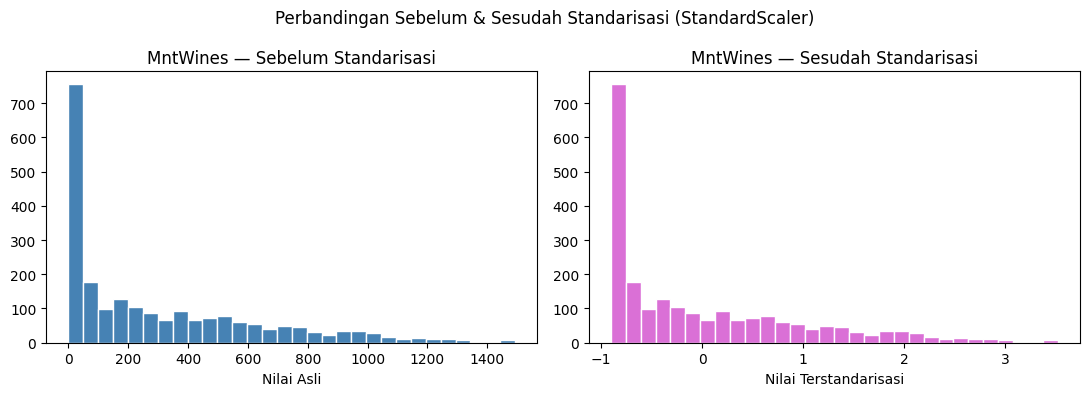

In [90]:
print("\n" + "=" * 50)
print("LANGKAH 7 - Standarisasi (StandardScaler: mean=0, std=1)")
print("=" * 50)

scaler_std = StandardScaler()
df_standardized = df[kolom_numerik].copy()
df_standardized[kolom_numerik] = scaler_std.fit_transform(df[kolom_numerik])

print("Sebelum standarisasi:")
print(df[kolom_numerik].describe().loc[["mean","std"]].round(2))
print("\nSesudah standarisasi:")
print(df_standardized[kolom_numerik].describe().loc[["mean","std"]].round(2))

# Visualisasi sebelum & sesudah standarisasi (contoh kolom rainfall)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["MntWines"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("MntWines — Sebelum Standarisasi")
axes[0].set_xlabel("Nilai Asli")

axes[1].hist(df_standardized["MntWines"], bins=30, color="orchid", edgecolor="white")
axes[1].set_title("MntWines — Sesudah Standarisasi")
axes[1].set_xlabel("Nilai Terstandarisasi")

plt.suptitle("Perbandingan Sebelum & Sesudah Standarisasi (StandardScaler)")
plt.tight_layout()
plt.savefig("step7_standarisasi.png")
plt.show()



In [91]:

df_standardized

,Income,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,...,AcceptedCmp1,AcceptedCmp2,Response,Age,Tenure_Days,Total_Spent,Total_Children,Total_Purchases,Total_Accepted,Kampanye_Lama_Diterima
0,0.287689,0.309118,0.977018,1.553315,1.689944,2.464405,1.482521,0.858552,0.352174,1.427120,...,-0.261180,-0.117363,2.381322,1.017915,1.975537,1.676120,-1.265454,1.309517,-0.438906,-0.438906
1,-0.260057,-0.382230,-0.871705,-0.636864,-0.717917,-0.651086,-0.634157,-0.733610,-0.167612,-1.125249,...,-0.261180,-0.117363,-0.419935,1.274437,-1.665742,-0.962274,1.403240,-1.187746,-0.438906,-0.438906
2,0.913505,-0.797039,0.357814,0.571511,-0.178378,1.346494,-0.147565,-0.034612,-0.687398,1.427120,...,-0.261180,-0.117363,-0.419935,0.333858,-0.172215,0.280592,-1.265454,1.032044,-0.438906,-0.438906
3,-1.174887,-0.797039,-0.871705,-0.561341,-0.655491,-0.504474,-0.585498,-0.753027,-0.167612,-0.760624,...,-0.261180,-0.117363,-0.419935,-1.290779,-1.923989,-0.919130,0.068893,-0.910272,-0.438906,-0.438906
4,0.294887,1.553545,-0.391748,0.420464,-0.218509,0.155277,-0.001587,-0.558861,1.391746,0.333248,...,-0.261180,-0.117363,-0.419935,-1.034258,-0.822136,-0.306824,0.068893,0.199623,-0.438906,-0.438906
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2211,0.430965,-0.105691,1.196257,0.420464,0.066867,0.081971,2.212410,3.945792,-0.167612,1.791745,...,-0.261180,-0.117363,-0.419935,0.162843,0.124769,1.218135,0.068893,0.477096,-0.438906,-0.438906
2212,0.560586,0.239984,0.298560,-0.662038,-0.610901,-0.687739,-0.658487,-0.694777,2.431318,1.427120,...,3.828782,-0.117363,-0.419935,1.958494,-1.941205,-0.270317,2.737586,0.338360,1.033897,1.033897
2213,0.233954,1.449843,1.785834,0.546336,0.222932,-0.101293,-0.366531,-0.384111,-0.687398,-0.760624,...,-0.261180,-0.117363,-0.419935,-1.034258,-0.847961,1.052198,-1.265454,0.754570,1.033897,1.033897
2214,0.803529,-1.419252,0.363739,0.093196,0.209555,0.778375,0.071402,0.334303,-0.167612,0.697872,...,-0.261180,-0.117363,-0.419935,1.103422,-0.843657,0.391770,0.068893,1.170781,-0.438906,-0.438906


In [92]:
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Age,Tenure_Days,Total_Spent,Total_Children,Total_Purchases,Total_Accepted,Status,Kampanye_Lama_Diterima,Education_encoded,Marital_Status_encoded
0,5524,1957,Graduation,Single,58138.0,0,0,2012-04-09,58,635,...,57,971,1617,0,22,0,Menerima,0,2,2
1,2174,1954,Graduation,Single,46344.0,1,1,2014-08-03,38,11,...,60,125,27,2,4,0,Menolak,0,2,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,49,472,776,0,20,0,Menolak,0,2,3
3,6182,1984,Graduation,Together,26646.0,1,0,2014-10-02,26,11,...,30,65,53,1,6,0,Menolak,0,2,3
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,33,321,422,1,14,0,Menolak,0,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2211,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,...,47,541,1341,1,16,0,Menolak,0,2,1
2212,4001,1946,PhD,Together,64014.0,2,1,2014-10-06,56,406,...,68,61,444,3,15,1,Menolak,1,4,3
2213,7270,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,...,33,315,1241,0,18,1,Menolak,1,2,0
2214,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,...,58,316,843,1,21,0,Menolak,0,3,3


In [93]:
for kolom in ['Response']:
    if kolom in kolom_numerik:
        kolom_numerik.remove(kolom)

print(kolom_numerik)
print(len(kolom_numerik), 'kolom numerik')



['Income', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Age', 'Tenure_Days', 'Total_Spent', 'Total_Children', 'Total_Purchases', 'Total_Accepted', 'Kampanye_Lama_Diterima']
25 kolom numerik



LANGKAH 8 - Split Data (80% training, 20% testing)
Total data    : 2208
Data training : 1766  (80%)
Data testing  : 442   (20%)


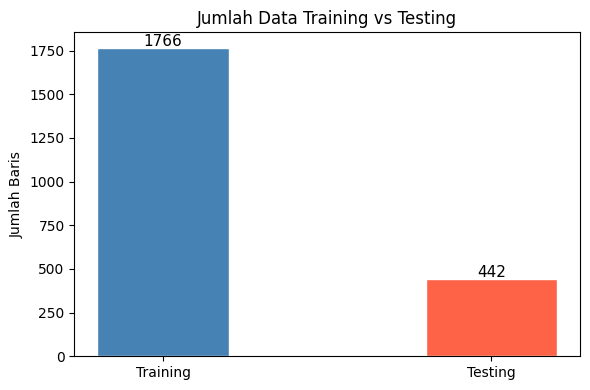

In [94]:
# ================================================
# LANGKAH 8 - Split Data: Training & Testing
# ================================================
print("\n" + "=" * 50)
print("LANGKAH 8 - Split Data (80% training, 20% testing)")
print("=" * 50)

X = df[kolom_numerik]           # fitur (input)
y = df["Response"]         # target (output)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20% untuk testing
    random_state=42,    # agar hasil bisa direproduksi
    stratify=y          # pastikan proporsi kelas sama di train & test
)

print(f"Total data    : {len(df)}")
print(f"Data training : {len(X_train)}  ({len(X_train)/len(df)*100:.0f}%)")
print(f"Data testing  : {len(X_test)}   ({len(X_test)/len(df)*100:.0f}%)")

# Visualisasi proporsi split
plt.figure(figsize=(6, 4))
plt.bar(["Training", "Testing"], [len(X_train), len(X_test)],
        color=["steelblue", "tomato"], edgecolor="white", width=0.4)
plt.title("Jumlah Data Training vs Testing")
plt.ylabel("Jumlah Baris")
for i, v in enumerate([len(X_train), len(X_test)]):
    plt.text(i, v + 10, str(v), ha="center", fontsize=11)
plt.tight_layout()
plt.savefig("step8_split_data.png")
plt.show()

In [95]:
# Simpan Hasil Processing ke CSV

print("\n" + "=" * 50)
print("LANGKAH 9 - Simpan Data yang Sudah Diproses")
print("=" * 50)

df_final = df.copy()
df_final["Education"]         = df["Education"].values
df_final["Education_encoded"] = df["Education_encoded"].values


df_final.to_csv("data_crop_processed.csv", index=False)
print("Data berhasil disimpan ke: data_crop_processed.csv")
print(f"Shape: {df_final.shape}")
print()
print(df_final.head())


LANGKAH 9 - Simpan Data yang Sudah Diproses
Data berhasil disimpan ke: data_crop_processed.csv
Shape: (2208, 36)

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  Age  Tenure_Days  Total_Spent  \
0  2012-04-09       58       635  ...   57          971         1617   
1  2014-08-03       38        11  ...   60          125           27   
2  2013-08-21       26       426  ...   49          472          776   
3  2014-10-02       26        11  ...   30           65           53   
4  2014-01-19       94       173  ...   33          321 

In [96]:
for kolom in ['Martial_Status_encoded', 'ID', 'Year_Birth', 'Education', 'Marital_Status', 'Education_encoded', 'Marital_Status_encoded']:
    if kolom in df_final:
        df_final.drop(columns=[kolom], inplace=True)

for kolom in ['Education_encoded', 'Marital_Status_encoded']:
    if kolom in df:
        df.drop(columns=[kolom], inplace=True)

print(df_final)
print(len(df_final), 'df_final')
print("Kolom terhapus dengan sukses!")

       Income  Kidhome  Teenhome Dt_Customer  Recency  MntWines  MntFruits  \
0     58138.0        0         0  2012-04-09       58       635         88   
1     46344.0        1         1  2014-08-03       38        11          1   
2     71613.0        0         0  2013-08-21       26       426         49   
3     26646.0        1         0  2014-10-02       26        11          4   
4     58293.0        1         0  2014-01-19       94       173         43   
...       ...      ...       ...         ...      ...       ...        ...   
2211  61223.0        0         1  2013-06-13       46       709         43   
2212  64014.0        2         1  2014-10-06       56       406          0   
2213  56981.0        0         0  2014-01-25       91       908         48   
2214  69245.0        0         1  2014-01-24        8       428         30   
2215  52869.0        1         1  2012-10-15       40        84          3   

      MntMeatProducts  MntFishProducts  MntSweetProducts  ...  

In [97]:
# ================================================
# MODELLING - Crop Recommendation Dataset
# Model: Decision Tree, Random Forest, AdaBoost,
#        XGBoost, SVM, Naive Bayes
# ================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

In [98]:
X

,Income,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,...,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Age,Tenure_Days,Total_Spent,Total_Children,Total_Purchases,Total_Accepted,Kampanye_Lama_Diterima
0,58138.0,58,635,88,546,172,88,88,3,8,...,0,0,0,57,971,1617,0,22,0,0
1,46344.0,38,11,1,6,2,1,6,2,1,...,0,0,0,60,125,27,2,4,0,0
2,71613.0,26,426,49,127,111,21,42,1,8,...,0,0,0,49,472,776,0,20,0,0
3,26646.0,26,11,4,20,10,3,5,2,2,...,0,0,0,30,65,53,1,6,0,0
4,58293.0,94,173,43,118,46,27,15,5,5,...,0,0,0,33,321,422,1,14,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2211,61223.0,46,709,43,182,42,118,247,2,9,...,0,0,0,47,541,1341,1,16,0,0
2212,64014.0,56,406,0,30,0,0,8,7,8,...,0,1,0,68,61,444,3,15,1,1
2213,56981.0,91,908,48,217,32,12,24,1,2,...,0,0,0,33,315,1241,0,18,1,1
2214,69245.0,8,428,30,214,80,30,61,2,6,...,0,0,0,58,316,843,1,21,0,0



MODEL 1 — DECISION TREE

[INSPECT] Parameter model:
  max_depth          : 6
  min_samples_split  : 6
  Jumlah node        : 85
  Kedalaman aktual   : 6
  Jumlah daun (leaf) : 43

[INSPECT] Feature Importance (seberapa penting tiap fitur):
  Kampanye_Lama_Diterima : 0.2575
  Recency         : 0.2029
  Tenure_Days     : 0.1137
  Total_Accepted  : 0.0798
  MntGoldProds    : 0.0463
  MntWines        : 0.0448
  Income          : 0.0415
  MntMeatProducts : 0.0367
  NumStorePurchases : 0.0331
  NumDealsPurchases : 0.0249
  MntFishProducts : 0.0224
  Total_Spent     : 0.0181
  Age             : 0.0169
  NumWebVisitsMonth : 0.0168
  MntSweetProducts : 0.0160
  Total_Purchases : 0.0087
  NumWebPurchases : 0.0075
  AcceptedCmp4    : 0.0066
  MntFruits       : 0.0055
  AcceptedCmp3    : 0.0000
  NumCatalogPurchases : 0.0000
  AcceptedCmp1    : 0.0000
  AcceptedCmp5    : 0.0000
  AcceptedCmp2    : 0.0000
  Total_Children  : 0.0000


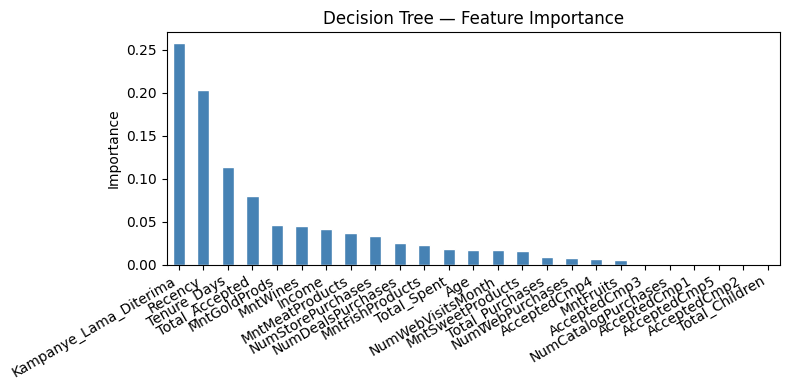

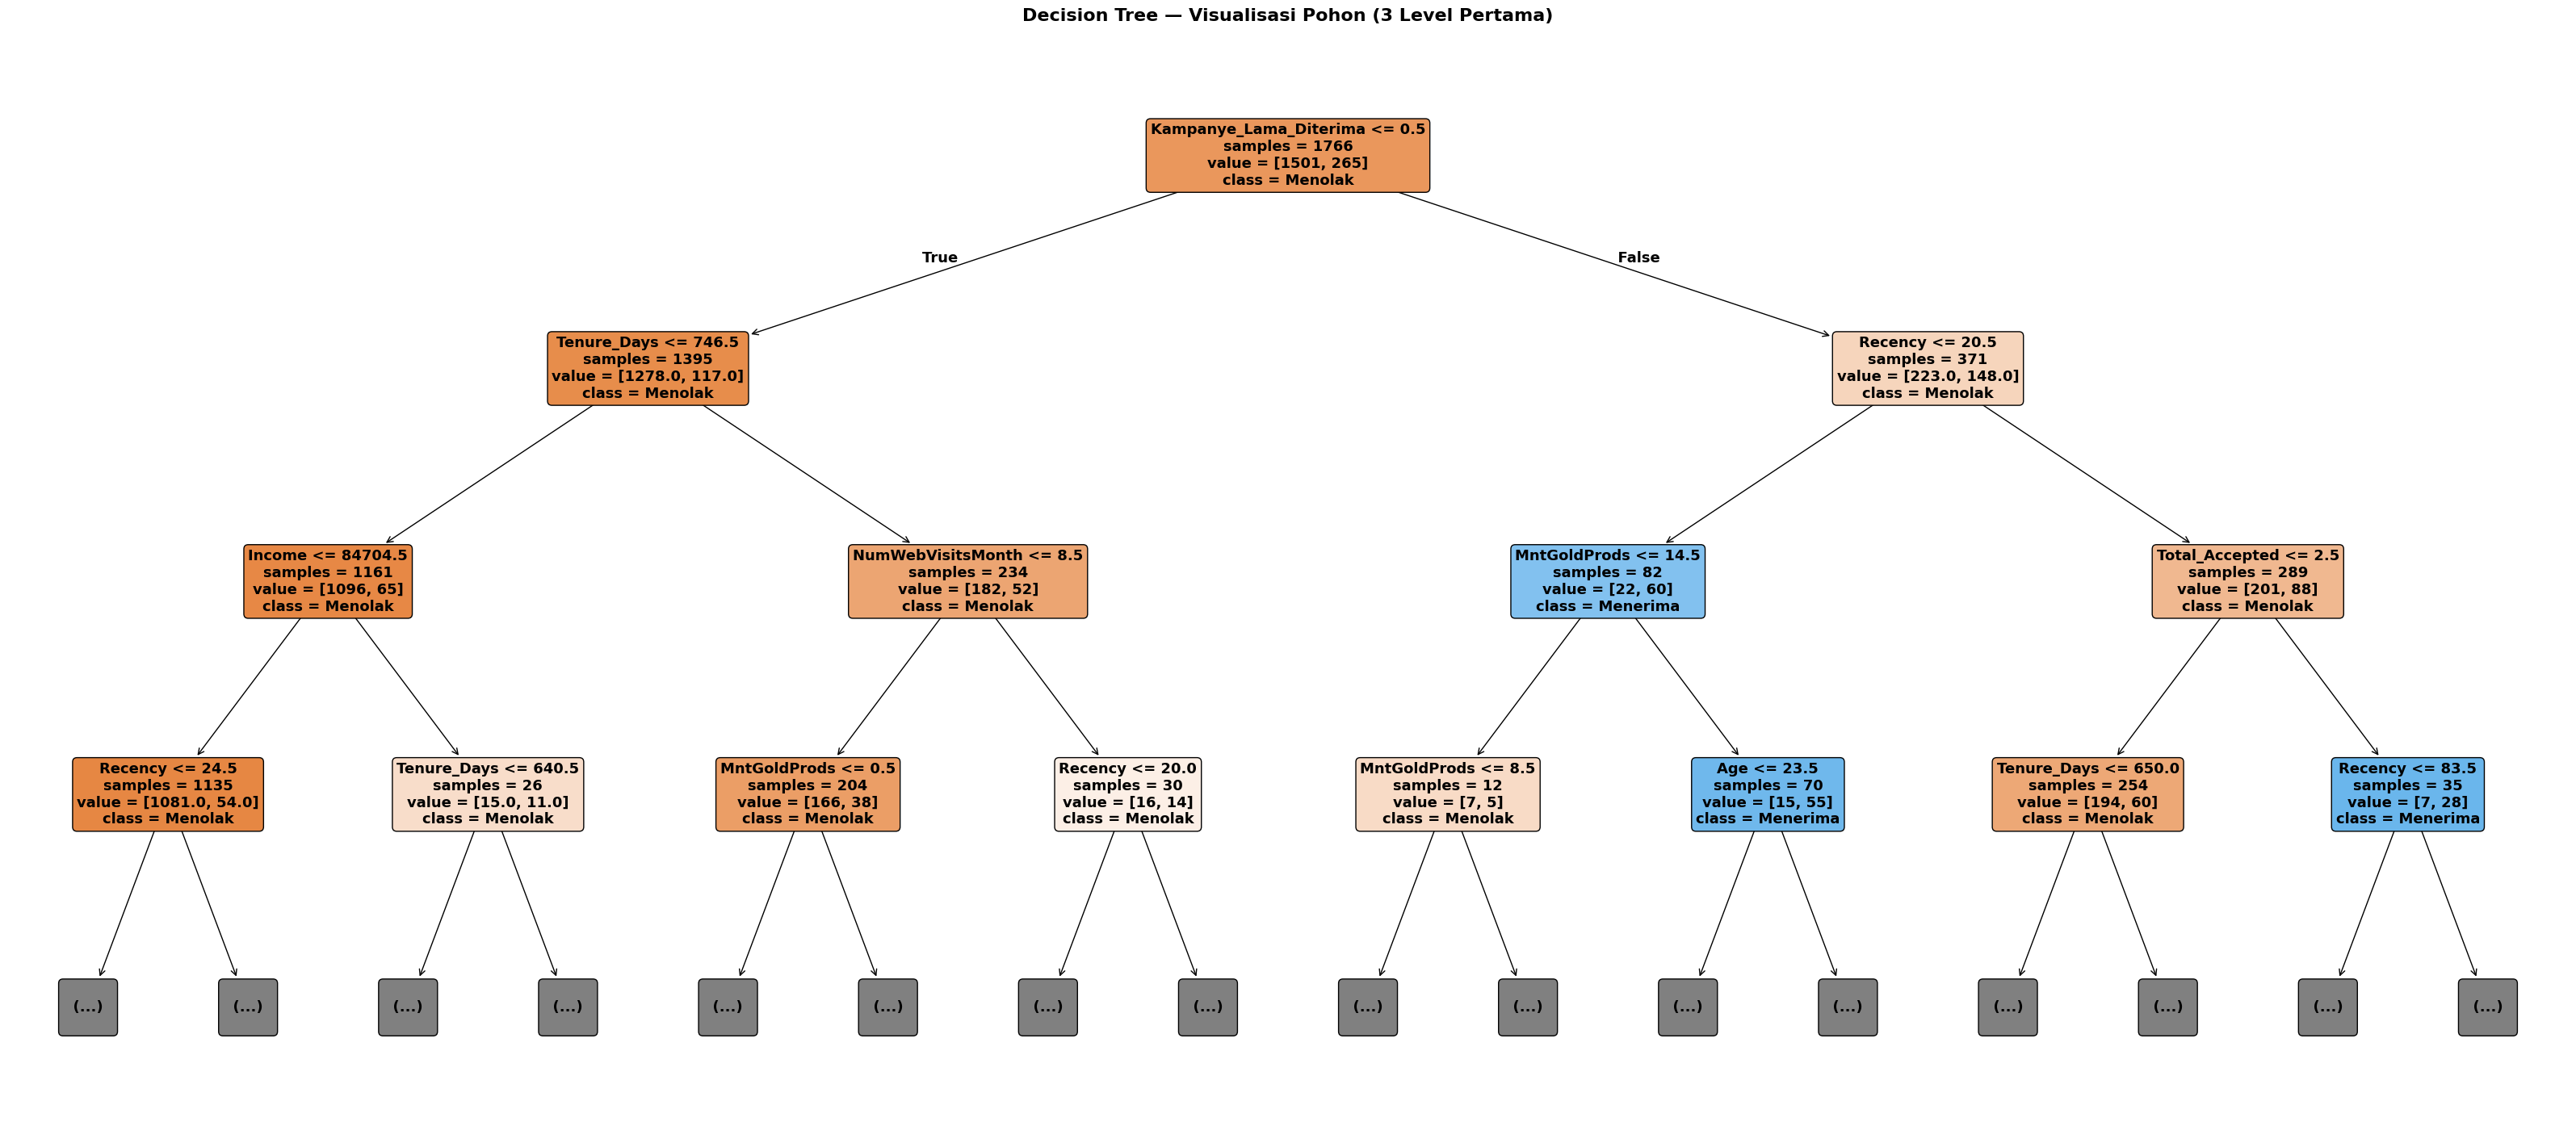


Prediksi 5 data pertama:
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak


In [99]:
print("\n" + "=" * 55)
print("MODEL 1 — DECISION TREE")
print("=" * 55)

dt = DecisionTreeClassifier(
    max_depth=6,
    min_samples_split=6,
    random_state=42
)
dt.fit(X_train, y_train)

print("\n[INSPECT] Parameter model:")
print(f"  max_depth          : {dt.max_depth}")
print(f"  min_samples_split  : {dt.min_samples_split}")
print(f"  Jumlah node        : {dt.tree_.node_count}")
print(f"  Kedalaman aktual   : {dt.get_depth()}")
print(f"  Jumlah daun (leaf) : {dt.get_n_leaves()}")

print("\n[INSPECT] Feature Importance (seberapa penting tiap fitur):")
fi_dt = pd.Series(dt.feature_importances_, index=X_train.columns).sort_values(ascending=False)
for nama, nilai in fi_dt.items():
    print(f"  {nama:15s} : {nilai:.4f}")


plt.figure(figsize=(8, 4))
fi_dt.plot(kind="bar", color="steelblue", edgecolor="white")
plt.title("Decision Tree — Feature Importance")
plt.ylabel("Importance")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("dt_feature_importance.png", dpi=150)
plt.show()


target_classes = ['Menolak', 'Menerima']

fig, ax = plt.subplots(figsize=(32, 14))


fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plot_tree(
    dt,
    feature_names=X_train.columns.tolist(),
    class_names=target_classes,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=13,
    impurity=False,
    proportion=False,
    precision=2,
    ax=ax,
)


for text_obj in ax.texts:
    text_obj.set_color("black")
    text_obj.set_fontweight("bold")

plt.title(
    "Decision Tree — Visualisasi Pohon (3 Level Pertama)",
    fontsize=16,
    fontweight="bold",
    color="black",
    pad=25
)
plt.tight_layout()
plt.savefig(
    "dt_tree_plot.png",
    dpi=250,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

print("\nPrediksi 5 data pertama:")
pred_dt = dt.predict(X_test)
for i in range(5):
    print(f"  Prediksi: {target_classes[pred_dt[i]]:15s} | Asli: {target_classes[y_test.values[i]]}")

PERBANDINGAN RATA-RATA PROFIL PELANGGAN


,Income,Total_Spent,Total_Children,Recency,Total_Purchases
Status,,,,,
Menerima,60187.75,986.66,0.65,35.29,15.34
Menolak,50489.69,539.94,1.00,51.48,12.07


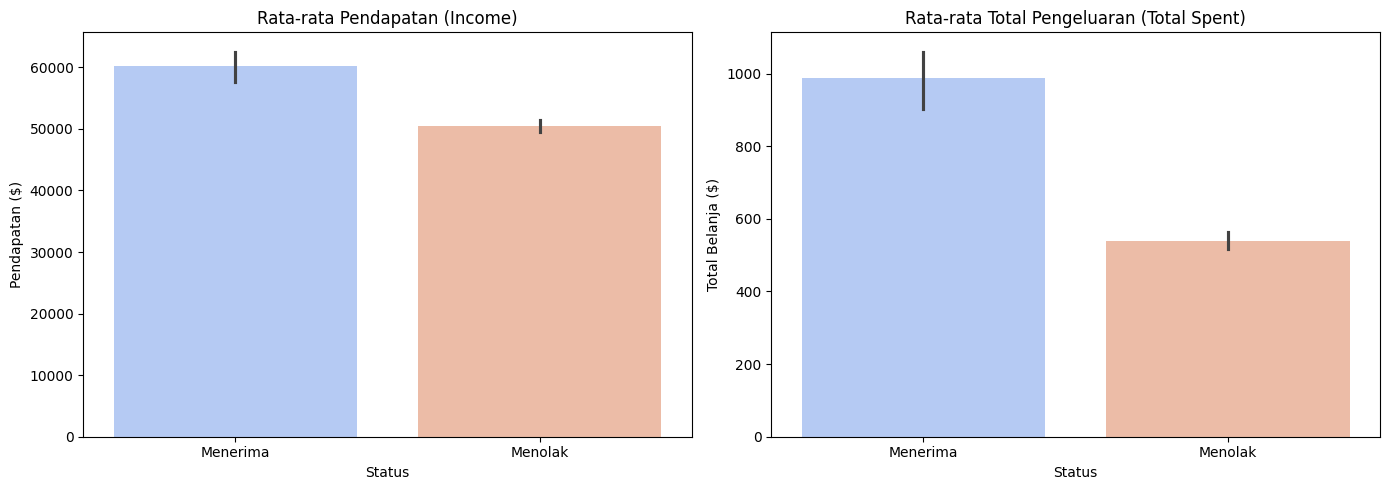

In [100]:
# Analisis perbandingan profil kelompok Menolak vs Menerima dan visualisasi
perbandingan = df.groupby('Status')[['Income', 'Total_Spent', 'Total_Children', 'Recency', 'Total_Purchases']].mean().round(2)
print("=======================================================")
print("PERBANDINGAN RATA-RATA PROFIL PELANGGAN")
print("=======================================================")
display(perbandingan)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='Status', y='Income', ax=axes[0], palette='coolwarm')
axes[0].set_title('Rata-rata Pendapatan (Income)')
axes[0].set_ylabel('Pendapatan ($)')

sns.barplot(data=df, x='Status', y='Total_Spent', ax=axes[1], palette='coolwarm')
axes[1].set_title('Rata-rata Total Pengeluaran (Total Spent)')
axes[1].set_ylabel('Total Belanja ($)')

plt.tight_layout()
plt.show()


MODEL 2 — RANDOM FOREST

[INSPECT] Parameter model:
  n_estimators (jumlah pohon) : 100
  max_depth                   : 10
  Jumlah kelas                : 2
  Jumlah fitur yang dipakai   : 25

[INSPECT] Contoh info 3 pohon pertama:
  Pohon ke-1: depth=10, node=229, daun=115
  Pohon ke-2: depth=10, node=235, daun=118
  Pohon ke-3: depth=10, node=213, daun=107

[INSPECT] Feature Importance:
  Recency         : 0.0984
  Tenure_Days     : 0.0865
  Kampanye_Lama_Diterima : 0.0726
  Total_Accepted  : 0.0707
  Total_Spent     : 0.0613
  Income          : 0.0581
  MntWines        : 0.0575
  MntMeatProducts : 0.0519
  MntGoldProds    : 0.0459
  Age             : 0.0449
  NumStorePurchases : 0.0365
  MntSweetProducts : 0.0360
  NumWebVisitsMonth : 0.0342
  MntFishProducts : 0.0332
  MntFruits       : 0.0329
  Total_Purchases : 0.0311
  NumCatalogPurchases : 0.0275
  NumWebPurchases : 0.0252
  NumDealsPurchases : 0.0227
  AcceptedCmp5    : 0.0205
  AcceptedCmp1    : 0.0174
  AcceptedCmp3    : 0.

<Figure size 800x400 with 0 Axes>

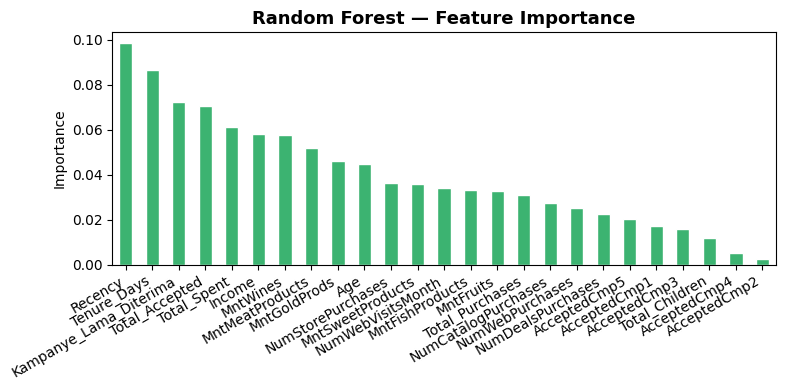

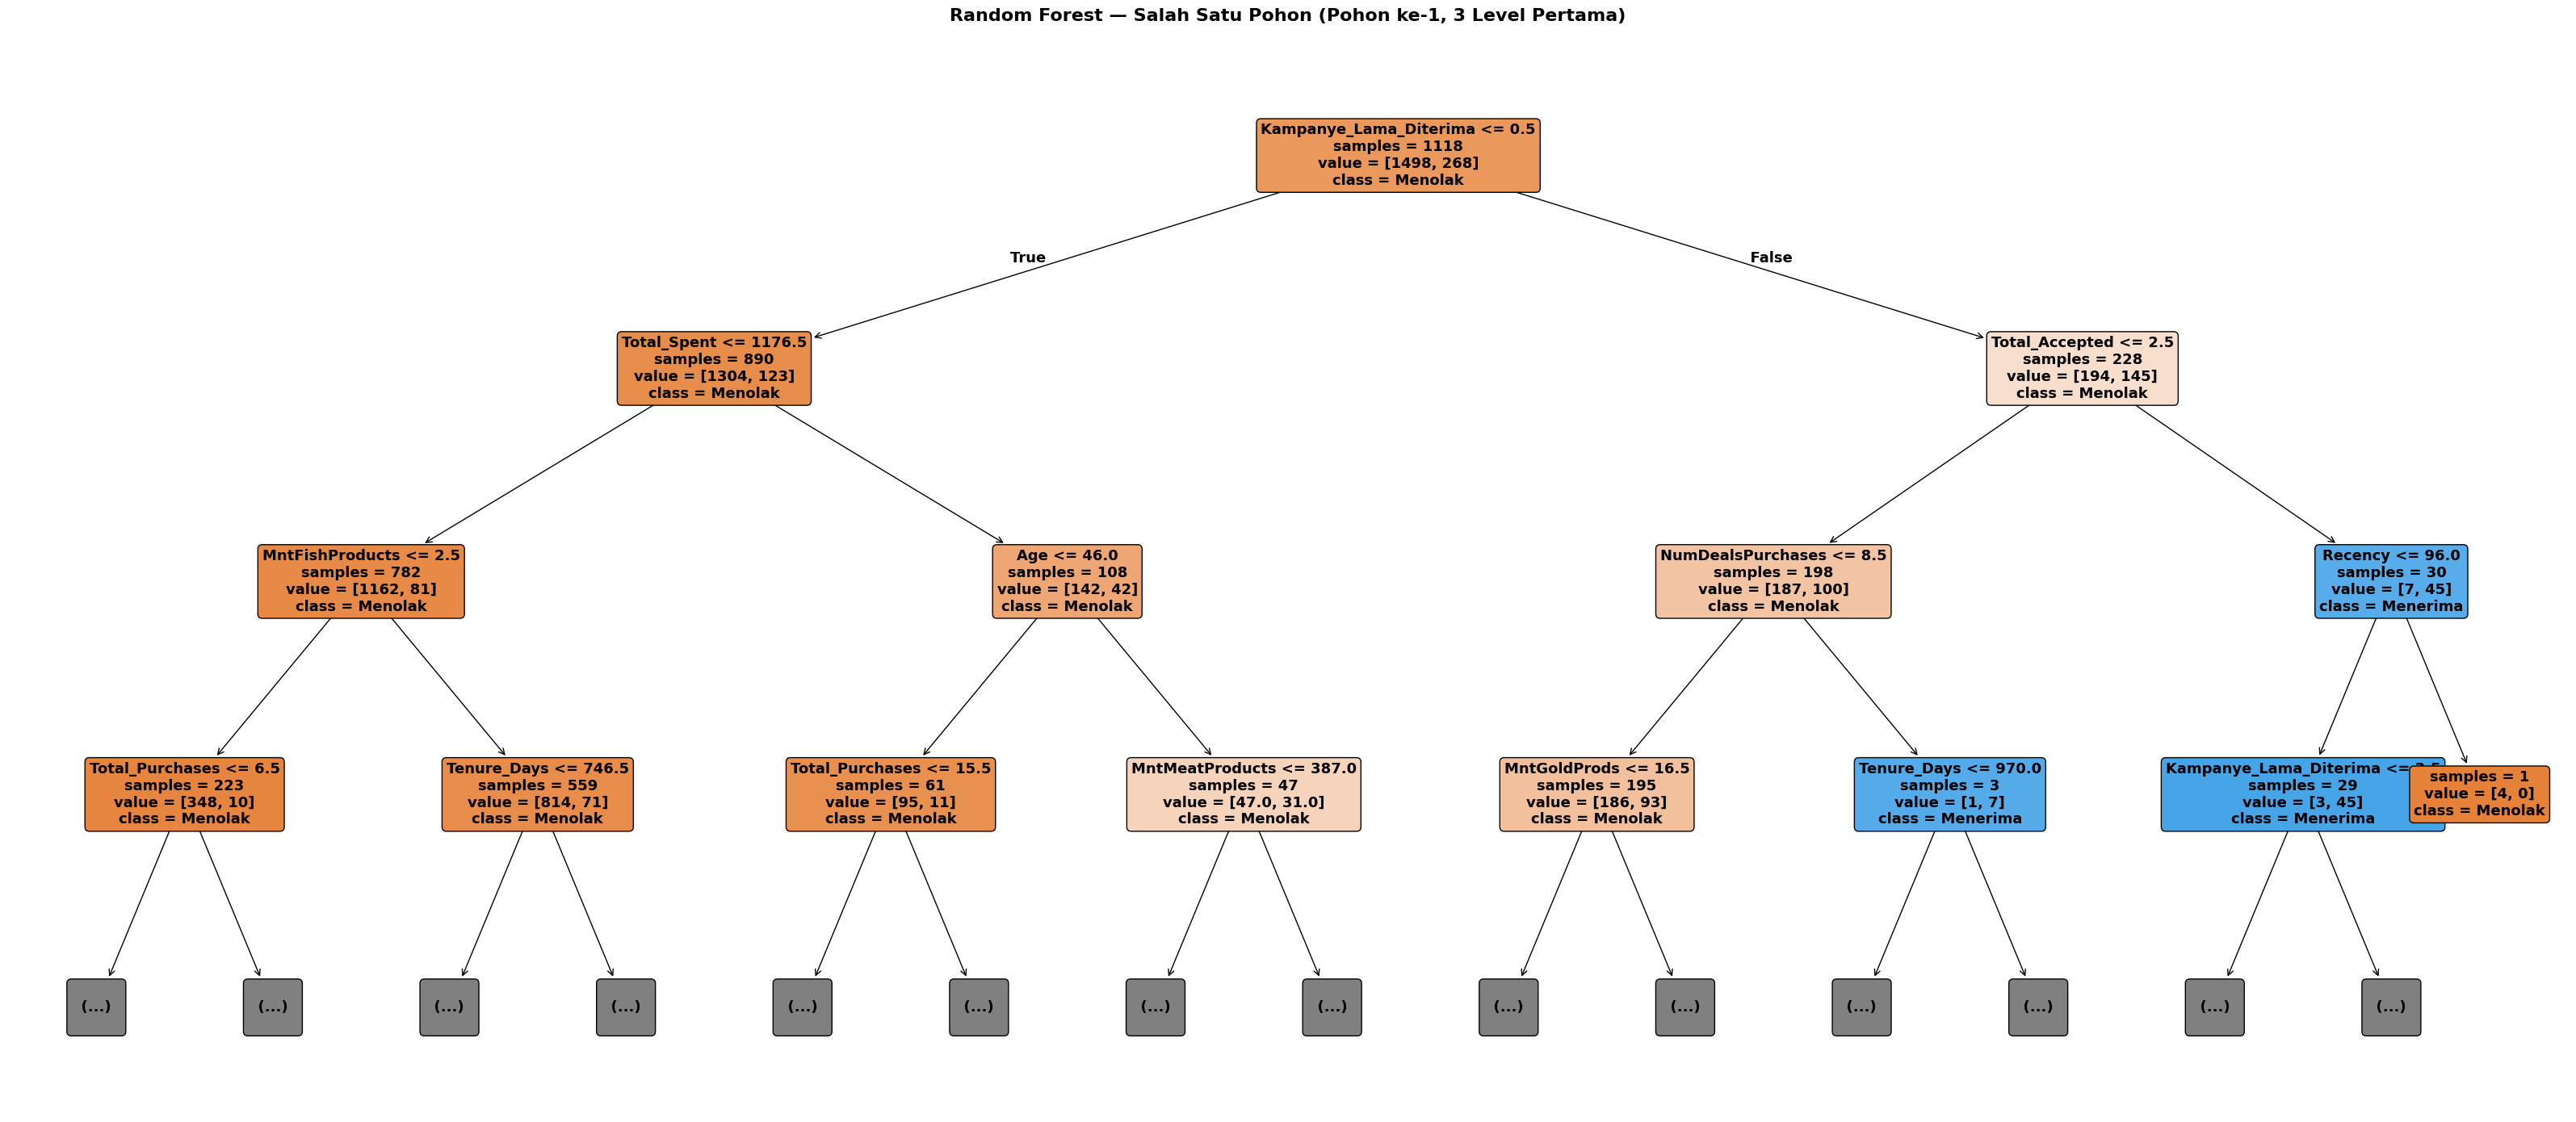


Prediksi 5 data pertama:
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak


In [101]:
print("\n" + "=" * 55)
print("MODEL 2 — RANDOM FOREST")
print("=" * 55)


target_classes = ['Menolak', 'Menerima']

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)
rf.fit(X_train, y_train)

# --- Inspect isi model ---
print("\n[INSPECT] Parameter model:")
print(f"  n_estimators (jumlah pohon) : {rf.n_estimators}")
print(f"  max_depth                   : {rf.max_depth}")
print(f"  Jumlah kelas                : {rf.n_classes_}")
print(f"  Jumlah fitur yang dipakai   : {rf.n_features_in_}")

print("\n[INSPECT] Contoh info 3 pohon pertama:")
for i, pohon in enumerate(rf.estimators_[:3]):
    print(f"  Pohon ke-{i+1}: "
          f"depth={pohon.get_depth()}, "
          f"node={pohon.tree_.node_count}, "
          f"daun={pohon.get_n_leaves()}")

print("\n[INSPECT] Feature Importance:")

fi_rf = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
for nama, nilai in fi_rf.items():
    print(f"  {nama:15s} : {nilai:.4f}")

# Visualisasi feature importance
plt.figure(figsize=(8, 4))
fig_fi, ax_fi = plt.subplots(figsize=(8, 4))
fig_fi.patch.set_facecolor("white")
ax_fi.set_facecolor("white")
fi_rf.plot(kind="bar", color="mediumseagreen", edgecolor="white", ax=ax_fi)
ax_fi.set_title("Random Forest — Feature Importance", fontsize=13, fontweight="bold", color="black")
ax_fi.set_ylabel("Importance", color="black")
ax_fi.tick_params(colors="black")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("rf_feature_importance.png", dpi=150, facecolor="white", bbox_inches="tight")
plt.show()


fig, ax = plt.subplots(figsize=(32, 14))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plot_tree(
    rf.estimators_[0],
    feature_names=X_train.columns.tolist(),
    class_names=target_classes,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=13,
    impurity=False,
    proportion=False,
    precision=2,
    ax=ax,
)


for text_obj in ax.texts:
    text_obj.set_color("black")
    text_obj.set_fontweight("bold")

plt.title(
    "Random Forest — Salah Satu Pohon (Pohon ke-1, 3 Level Pertama)",
    fontsize=16,
    fontweight="bold",
    color="black",
    pad=25
)
plt.tight_layout()
plt.savefig(
    "rf_one_tree.png",
    dpi=250,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

print("\nPrediksi 5 data pertama:")
pred_rf = rf.predict(X_test)
for i in range(5):
    print(f"  Prediksi: {target_classes[pred_rf[i]]:15s} | Asli: {target_classes[y_test.values[i]]}")


MODEL 3 — ADABOOST

[INSPECT] Parameter model:
  n_estimators  : 100
  learning_rate : 0.5
  Estimator dasar (base): DecisionTreeClassifier

[INSPECT] Bobot (weight) tiap estimator (10 pertama):
  Estimator ke- 1 : bobot = 0.8671
  Estimator ke- 2 : bobot = 0.5895
  Estimator ke- 3 : bobot = 0.3759
  Estimator ke- 4 : bobot = 0.3910
  Estimator ke- 5 : bobot = 0.3611
  Estimator ke- 6 : bobot = 0.1513
  Estimator ke- 7 : bobot = 0.1710
  Estimator ke- 8 : bobot = 0.1167
  Estimator ke- 9 : bobot = 0.1442
  Estimator ke-10 : bobot = 0.2085

[INSPECT] Error tiap estimator (10 pertama):
  Estimator ke- 1 : error = 0.1501
  Estimator ke- 2 : error = 0.2352
  Estimator ke- 3 : error = 0.3204
  Estimator ke- 4 : error = 0.3139
  Estimator ke- 5 : error = 0.3269
  Estimator ke- 6 : error = 0.4249
  Estimator ke- 7 : error = 0.4153
  Estimator ke- 8 : error = 0.4419
  Estimator ke- 9 : error = 0.4284
  Estimator ke-10 : error = 0.3972


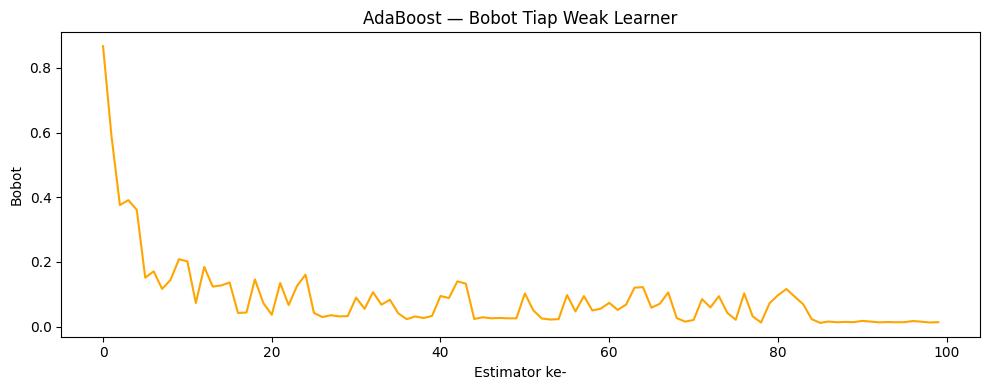

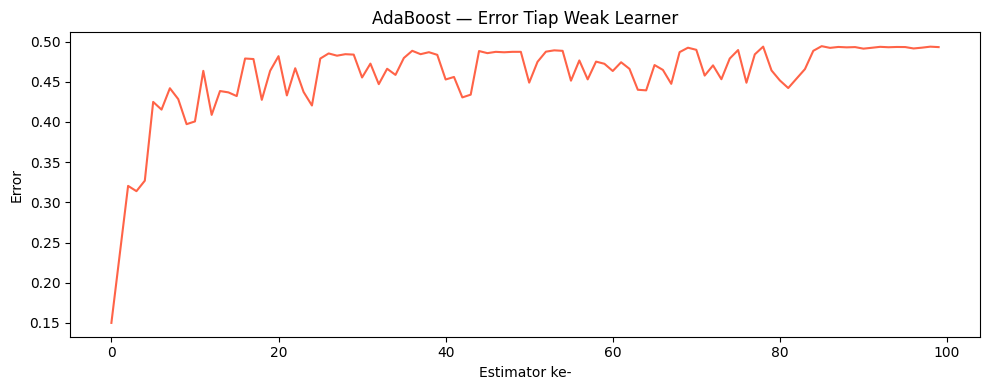


Prediksi 5 data pertama:
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak


In [102]:
print("\n" + "=" * 55)
print("MODEL 3 — ADABOOST")
print("=" * 55)


target_classes = ['Menolak', 'Menerima']

ada = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)
ada.fit(X_train, y_train)

# --- Inspect isi model ---
print("\n[INSPECT] Parameter model:")
print(f"  n_estimators  : {ada.n_estimators}")
print(f"  learning_rate : {ada.learning_rate}")
print(f"  Estimator dasar (base): {type(ada.estimator_).__name__}")

print("\n[INSPECT] Bobot (weight) tiap estimator (10 pertama):")
for i, bobot in enumerate(ada.estimator_weights_[:10]):
    print(f"  Estimator ke-{i+1:2d} : bobot = {bobot:.4f}")

print("\n[INSPECT] Error tiap estimator (10 pertama):")
for i, err in enumerate(ada.estimator_errors_[:10]):
    print(f"  Estimator ke-{i+1:2d} : error = {err:.4f}")

# Visualisasi bobot estimator
plt.figure(figsize=(10, 4))
plt.plot(ada.estimator_weights_, color="orange", linewidth=1.5)
plt.title("AdaBoost — Bobot Tiap Weak Learner")
plt.xlabel("Estimator ke-")
plt.ylabel("Bobot")
plt.tight_layout()
plt.savefig("ada_weights.png")
plt.show()

# Visualisasi error tiap estimator
plt.figure(figsize=(10, 4))
plt.plot(ada.estimator_errors_, color="tomato", linewidth=1.5)
plt.title("AdaBoost — Error Tiap Weak Learner")
plt.xlabel("Estimator ke-")
plt.ylabel("Error")
plt.tight_layout()
plt.savefig("ada_errors.png")
plt.show()

print("\nPrediksi 5 data pertama:")
pred_ada = ada.predict(X_test)
for i in range(5):

    print(f"  Prediksi: {target_classes[pred_ada[i]]:15s} | Asli: {target_classes[y_test.values[i]]}")


MODEL 4 — XGBOOST

[INSPECT] Parameter model:
  n_estimators  : 100
  max_depth     : 5
  learning_rate : 0.1
  Jumlah fitur  : 25

[INSPECT] Feature Importance (weight = berapa kali fitur dipakai untuk split):
  Total_Accepted  : 0.2339
  AcceptedCmp4    : 0.0828
  Recency         : 0.0587
  Tenure_Days     : 0.0586
  Total_Children  : 0.0477
  AcceptedCmp5    : 0.0425
  NumStorePurchases : 0.0405
  Income          : 0.0400
  MntMeatProducts : 0.0370
  NumCatalogPurchases : 0.0341
  NumDealsPurchases : 0.0330
  Total_Spent     : 0.0317
  NumWebVisitsMonth : 0.0285
  MntWines        : 0.0282
  AcceptedCmp3    : 0.0267
  MntGoldProds    : 0.0239
  MntFishProducts : 0.0236
  AcceptedCmp1    : 0.0233
  Total_Purchases : 0.0228
  NumWebPurchases : 0.0226
  MntFruits       : 0.0222
  MntSweetProducts : 0.0205
  Age             : 0.0173
  AcceptedCmp2    : 0.0000
  Kampanye_Lama_Diterima : 0.0000


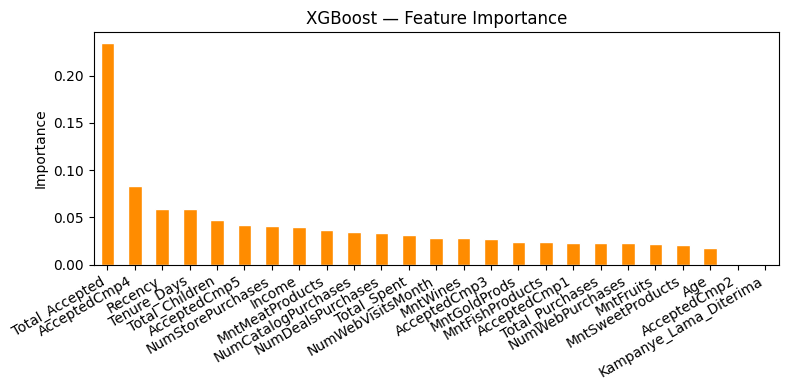

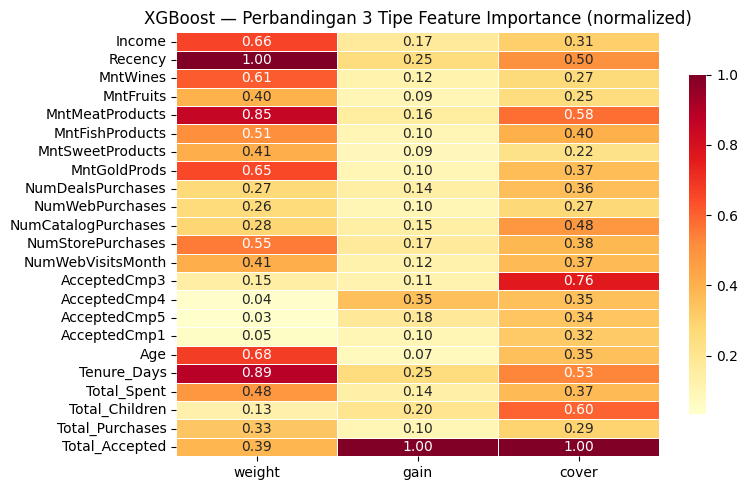


Penjelasan 3 tipe importance XGBoost:
  weight = berapa kali fitur dipakai untuk split
  gain   = rata-rata gain (peningkatan) saat fitur dipakai
  cover  = rata-rata jumlah sampel yang terdampak split

Prediksi 5 data pertama:
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak
  Prediksi: Menolak         | Asli: Menolak


In [103]:
print("\n" + "=" * 55)
print("MODEL 4 — XGBOOST")
print("=" * 55)


target_classes = ['Menolak', 'Menerima']

xgb = XGBClassifier(
    n_estimators=100,     # jumlah pohon
    max_depth=5,          # kedalaman tiap pohon
    learning_rate=0.1,    # langkah belajar
    use_label_encoder=False,
    eval_metric="mlogloss",
    random_state=42,
    verbosity=0
)
xgb.fit(X_train, y_train)

# --- Inspect isi model ---
print("\n[INSPECT] Parameter model:")
print(f"  n_estimators  : {xgb.n_estimators}")
print(f"  max_depth     : {xgb.max_depth}")
print(f"  learning_rate : {xgb.learning_rate}")
print(f"  Jumlah fitur  : {xgb.n_features_in_}")

print("\n[INSPECT] Feature Importance (weight = berapa kali fitur dipakai untuk split):")

fi_xgb = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False)
for nama, nilai in fi_xgb.items():
    print(f"  {nama:15s} : {nilai:.4f}")

# Visualisasi feature importance
plt.figure(figsize=(8, 4))
fi_xgb.plot(kind="bar", color="darkorange", edgecolor="white")
plt.title("XGBoost — Feature Importance")
plt.ylabel("Importance")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("xgb_feature_importance.png")
plt.show()


fi_tipe = {
    "weight"  : xgb.get_booster().get_score(importance_type="weight"),
    "gain"    : xgb.get_booster().get_score(importance_type="gain"),
    "cover"   : xgb.get_booster().get_score(importance_type="cover"),
}

df_fi = pd.DataFrame(fi_tipe).fillna(0)

# Normalisasi
df_fi_norm = df_fi.div(df_fi.max())

plt.figure(figsize=(8, 5))
sns.heatmap(df_fi_norm, annot=True, fmt=".2f", cmap="YlOrRd",
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("XGBoost — Perbandingan 3 Tipe Feature Importance (normalized)")
plt.tight_layout()
plt.savefig("xgb_importance_heatmap.png")
plt.show()

print("\nPenjelasan 3 tipe importance XGBoost:")
print("  weight = berapa kali fitur dipakai untuk split")
print("  gain   = rata-rata gain (peningkatan) saat fitur dipakai")
print("  cover  = rata-rata jumlah sampel yang terdampak split")

print("\nPrediksi 5 data pertama:")
pred_xgb = xgb.predict(X_test)
for i in range(5):

    print(f"  Prediksi: {target_classes[pred_xgb[i]]:15s} | Asli: {target_classes[y_test.values[i]]}")


MODEL 5 — SVM (Support Vector Machine)

[INSPECT] Parameter model:
  kernel : rbf
  C      : 1.0
  gamma  : scale

[INSPECT] Jumlah Support Vector:
  Total support vector : 592
  Menolak         : 327 support vector
  Menerima        : 265 support vector


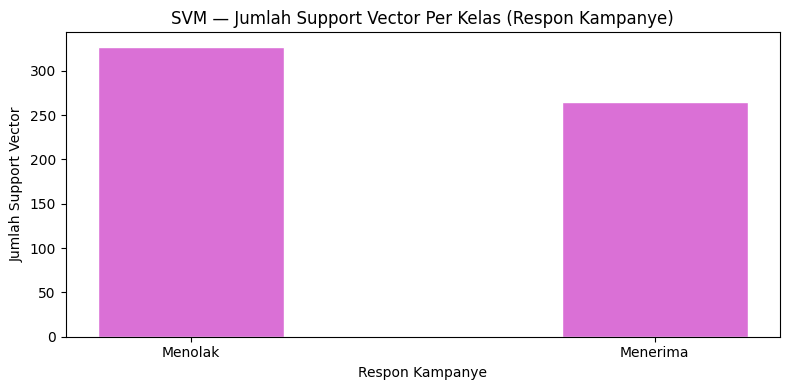


[INSPECT] Probabilitas prediksi 5 data pertama:
  Data ke-1: Prediksi=Menolak         | Keyakinan=86.1% | Asli=Menolak
  Data ke-2: Prediksi=Menolak         | Keyakinan=86.7% | Asli=Menolak
  Data ke-3: Prediksi=Menolak         | Keyakinan=86.1% | Asli=Menolak
  Data ke-4: Prediksi=Menolak         | Keyakinan=85.5% | Asli=Menolak
  Data ke-5: Prediksi=Menolak         | Keyakinan=88.4% | Asli=Menolak


In [104]:
print("\n" + "=" * 55)
print("MODEL 5 — SVM (Support Vector Machine)")
print("=" * 55)

target_classes = ['Menolak', 'Menerima']

svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True
)
svm.fit(X_train, y_train)

print("\n[INSPECT] Parameter model:")
print(f"  kernel : {svm.kernel}")
print(f"  C      : {svm.C}")
print(f"  gamma  : {svm.gamma}")

print(f"\n[INSPECT] Jumlah Support Vector:")
print(f"  Total support vector : {svm.n_support_.sum()}")

for kelas, jumlah in zip(target_classes, svm.n_support_):
    print(f"  {kelas:15s} : {jumlah} support vector")

# Visualisasi jumlah support vector per kelas
plt.figure(figsize=(8, 4))

plt.bar(target_classes, svm.n_support_, color="orchid", edgecolor="white", width=0.4)
plt.title("SVM — Jumlah Support Vector Per Kelas (Respon Kampanye)")
plt.xlabel("Respon Kampanye")
plt.ylabel("Jumlah Support Vector")
plt.tight_layout()
plt.savefig("svm_support_vectors.png")
plt.show()

print("\n[INSPECT] Probabilitas prediksi 5 data pertama:")
prob_svm = svm.predict_proba(X_test[:5])
pred_svm = svm.predict(X_test)
for i in range(5):
    idx_max   = np.argmax(prob_svm[i])
    prob_max  = prob_svm[i][idx_max]

    print(f"  Data ke-{i+1}: Prediksi={target_classes[pred_svm[i]]:15s} "
          f"| Keyakinan={prob_max*100:.1f}% "
          f"| Asli={target_classes[y_test.values[i]]}")


VISUALISASI HYPERPLANE SVM

[INFO] Memilih 2 fitur terbaik untuk visualisasi 2D...
  Fitur terpilih: Total_Accepted  &  Kampanye_Lama_Diterima
[INFO] Melatih SVM dengan 2 fitur untuk visualisasi...


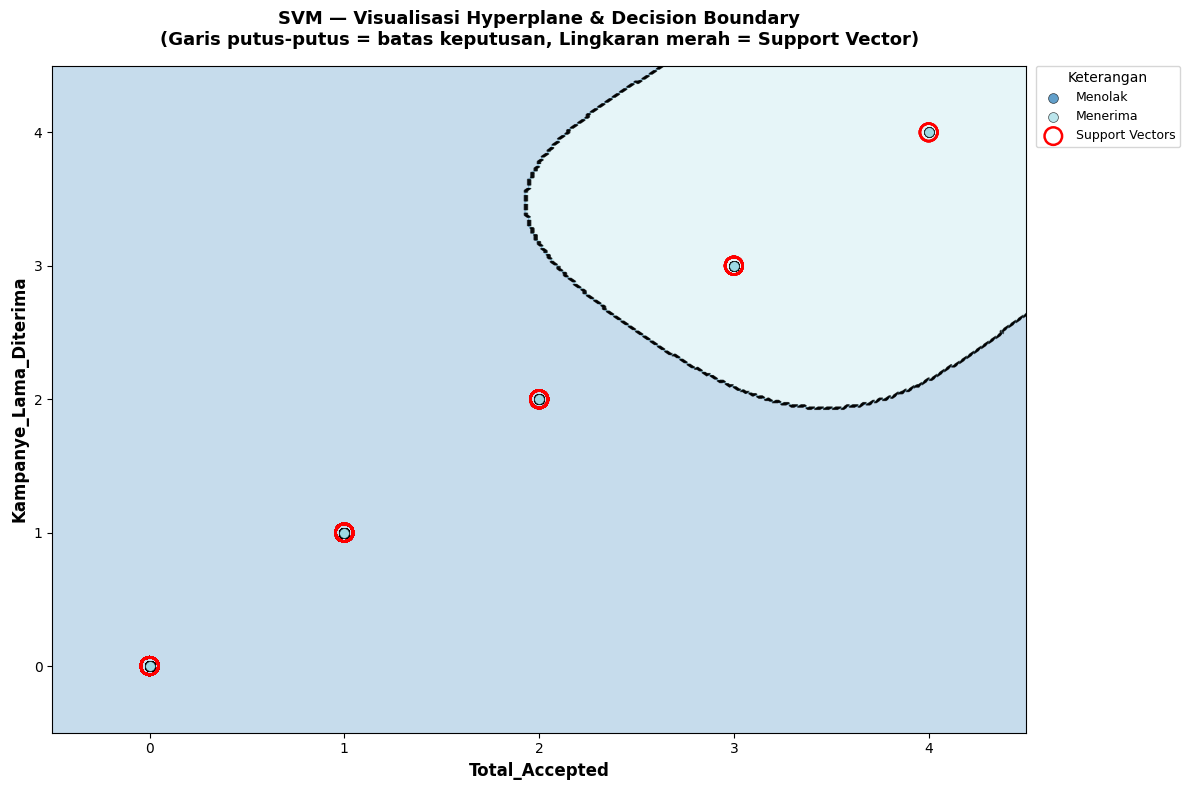

[INFO] Gambar hyperplane disimpan → svm_hyperplane.png


In [105]:
print("\n" + "=" * 55)
print("VISUALISASI HYPERPLANE SVM")
print("=" * 55)

from sklearn.feature_selection import SelectKBest, f_classif


target_classes = ['Menolak', 'Menerima']


X_train_np = X_train.values if hasattr(X_train, 'values') else X_train
X_test_np  = X_test.values  if hasattr(X_test,  'values') else X_test

print("\n[INFO] Memilih 2 fitur terbaik untuk visualisasi 2D...")

selector = SelectKBest(f_classif, k=2)
selector.fit(X_train_np, y_train)
idx_fitur     = selector.get_support(indices=True)
nama_fitur_2d = [X_train.columns[i] for i in idx_fitur]

print(f"  Fitur terpilih: {nama_fitur_2d[0]}  &  {nama_fitur_2d[1]}")


X_train_2d = X_train_np[:, idx_fitur]
X_test_2d  = X_test_np[:,  idx_fitur]


print("[INFO] Melatih SVM dengan 2 fitur untuk visualisasi...")

svm_2d = SVC(kernel="rbf", C=1.0, gamma="scale")
svm_2d.fit(X_train_2d, y_train)


margin = 0.5
x_min = X_train_2d[:, 0].min() - margin
x_max = X_train_2d[:, 0].max() + margin
y_min = X_train_2d[:, 1].min() - margin
y_max = X_train_2d[:, 1].max() + margin

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)


# Gambar hyperplane

kelas_unik  = np.unique(y_train)
n_kelas     = len(kelas_unik)
palet       = plt.cm.get_cmap("tab20", n_kelas)

y_train_np = y_train.values if hasattr(y_train, 'values') else y_train

fig, ax = plt.subplots(figsize=(12, 8))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")


ax.contourf(xx, yy, Z, alpha=0.25, cmap=palet)


ax.contour(xx, yy, Z, colors="black", linewidths=1.2, linestyles="--", alpha=0.6)


for idx_kelas, kelas in enumerate(kelas_unik):
    mask = y_train_np == kelas
    ax.scatter(
        X_train_2d[mask, 0],
        X_train_2d[mask, 1],
        label=target_classes[kelas],
        color=palet(idx_kelas),
        edgecolors="black",
        linewidths=0.5,
        s=50,
        alpha=0.7,
        zorder=3
    )


sv = svm_2d.support_vectors_
ax.scatter(
    sv[:, 0], sv[:, 1],
    s=160,
    facecolors="none",
    edgecolors="red",
    linewidths=1.8,
    label="Support Vectors",
    zorder=4
)

ax.set_xlabel(nama_fitur_2d[0], fontsize=12, fontweight="bold", color="black")
ax.set_ylabel(nama_fitur_2d[1], fontsize=12, fontweight="bold", color="black")
ax.set_title(
    "SVM — Visualisasi Hyperplane & Decision Boundary\n"
    "(Garis putus-putus = batas keputusan, Lingkaran merah = Support Vector)",
    fontsize=13, fontweight="bold", color="black", pad=15
)
ax.tick_params(colors="black")
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    borderaxespad=0,
    fontsize=9,
    title="Keterangan",
    title_fontsize=10,
    frameon=True
)

plt.tight_layout()
plt.savefig("svm_hyperplane.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()
print("[INFO] Gambar hyperplane disimpan → svm_hyperplane.png")


MODEL 6 — NAIVE BAYES (Gaussian)

[INSPECT] Parameter model:
  Jenis distribusi : Gaussian (Normal)
  Jumlah kelas     : 2

[INSPECT] Jumlah sampel training per kelas:
  Menolak         : 1501 sampel
  Menerima        : 265 sampel

[INSPECT] Prior probability tiap kelas (peluang awal sebelum lihat data):
  Menolak         : 0.8499  (85.0%)
  Menerima        : 0.1501  (15.0%)

[INSPECT] Rata-rata (mean) tiap fitur per kelas (5 kelas pertama):
             Income  Recency  MntWines  MntFruits  MntMeatProducts  \
Menolak   50626.258   51.301   269.857     23.992          144.800   
Menerima  59148.468   35.445   498.347     37.808          285.974   

          MntFishProducts  MntSweetProducts  MntGoldProds  NumDealsPurchases  \
Menolak            34.123            25.039        40.207              2.350   
Menerima           49.751            35.377        58.491              2.294   

          NumWebPurchases  ...  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  \
Menolak             3.895

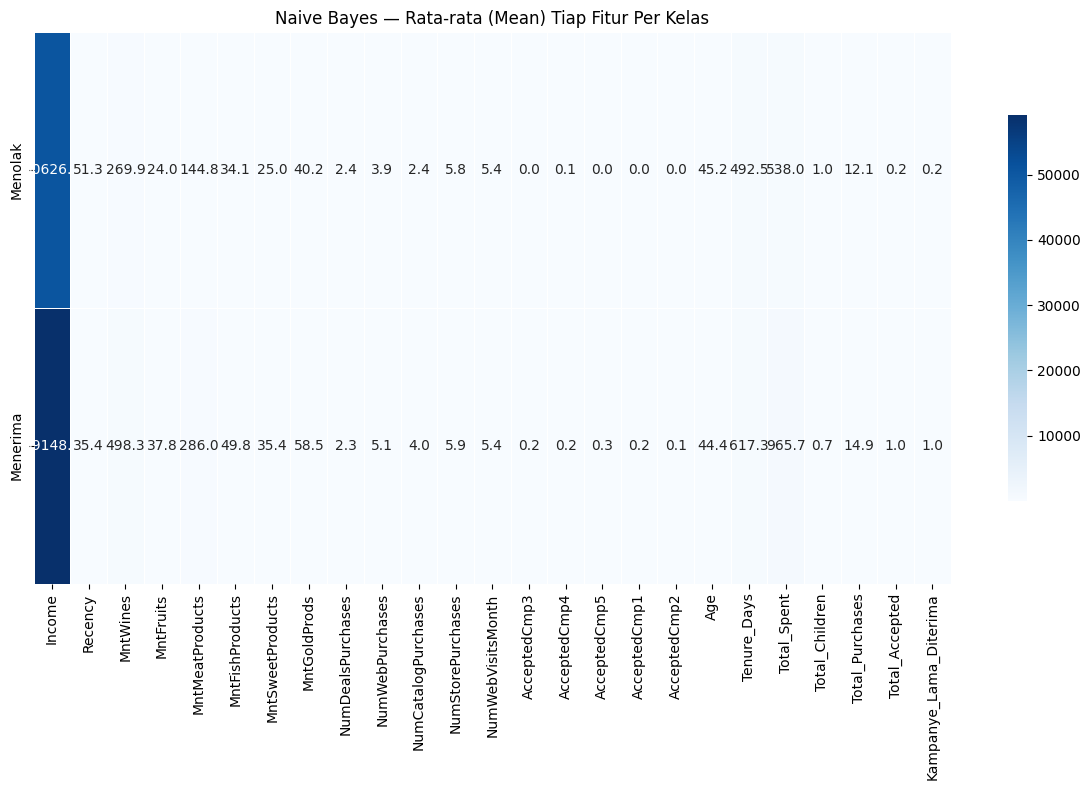


Prediksi 5 data pertama:
  Data ke-1: Prediksi=Menolak         | Keyakinan=100.0% | Asli=Menolak
  Data ke-2: Prediksi=Menolak         | Keyakinan=100.0% | Asli=Menolak
  Data ke-3: Prediksi=Menolak         | Keyakinan=99.9% | Asli=Menolak
  Data ke-4: Prediksi=Menolak         | Keyakinan=99.2% | Asli=Menolak
  Data ke-5: Prediksi=Menolak         | Keyakinan=100.0% | Asli=Menolak


In [106]:
print("\n" + "=" * 55)
print("MODEL 6 — NAIVE BAYES (Gaussian)")
print("=" * 55)


target_classes = ['Menolak', 'Menerima']

nb = GaussianNB()
nb.fit(X_train, y_train)

# --- Inspect isi model ---
print("\n[INSPECT] Parameter model:")
print(f"  Jenis distribusi : Gaussian (Normal)")
print(f"  Jumlah kelas     : {nb.class_count_.shape[0]}")

print("\n[INSPECT] Jumlah sampel training per kelas:")
for kelas, jumlah in zip(target_classes, nb.class_count_):
    print(f"  {kelas:15s} : {int(jumlah)} sampel")

print("\n[INSPECT] Prior probability tiap kelas (peluang awal sebelum lihat data):")
for kelas, prior in zip(target_classes, nb.class_prior_):
    print(f"  {kelas:15s} : {prior:.4f}  ({prior*100:.1f}%)")

print("\n[INSPECT] Rata-rata (mean) tiap fitur per kelas (5 kelas pertama):")
df_mean = pd.DataFrame(nb.theta_, columns=X_train.columns, index=target_classes)
print(df_mean.head(5).round(3))

print("\n[INSPECT] Variansi (var) tiap fitur per kelas (5 kelas pertama):")
df_var = pd.DataFrame(nb.var_, columns=X_train.columns, index=target_classes)
print(df_var.head(5).round(3))

# Visualisasi mean tiap fitur per kelas (heatmap)
plt.figure(figsize=(12, 8))
sns.heatmap(df_mean, annot=True, fmt=".1f", cmap="Blues",
            linewidths=0.4, cbar_kws={"shrink": 0.7})
plt.title("Naive Bayes — Rata-rata (Mean) Tiap Fitur Per Kelas")
plt.tight_layout()
plt.savefig("nb_mean_heatmap.png")
plt.show()

print("\nPrediksi 5 data pertama:")
pred_nb = nb.predict(X_test)
prob_nb = nb.predict_proba(X_test[:5])
for i in range(5):
    idx_max  = np.argmax(prob_nb[i])
    prob_max = prob_nb[i][idx_max]
    print(f"  Data ke-{i+1}: Prediksi={target_classes[pred_nb[i]]:15s} "
          f"| Keyakinan={prob_max*100:.1f}% "
          f"| Asli={target_classes[y_test.values[i]]}")

In [107]:
print("\n" + "=" * 55)
print("RINGKASAN SEMUA MODEL")
print("=" * 55)
print(f"{'Model':<20} {'Kelas':>6} {'Fitur':>6}")
print("-" * 36)
print(f"{'Decision Tree':<20} {dt.n_classes_:>6} {dt.n_features_in_:>6}")
print(f"{'Random Forest':<20} {rf.n_classes_:>6} {rf.n_features_in_:>6}")
print(f"{'AdaBoost':<20} {len(ada.classes_):>6} {ada.n_features_in_:>6}")
print(f"{'XGBoost':<20} {xgb.n_classes_:>6} {xgb.n_features_in_:>6}")
print(f"{'SVM':<20} {len(svm.classes_):>6} {svm.n_features_in_:>6}")
print(f"{'Naive Bayes':<20} {len(nb.classes_):>6} {nb.n_features_in_:>6}")
print("\nSemua model berhasil dilatih!")
print("File gambar tersimpan di folder yang sama.")


RINGKASAN SEMUA MODEL
Model                 Kelas  Fitur
------------------------------------
Decision Tree             2     25
Random Forest             2     25
AdaBoost                  2     25
XGBoost                   2     25
SVM                       2     25
Naive Bayes               2     25

Semua model berhasil dilatih!
File gambar tersimpan di folder yang sama.


In [108]:
# Evaluasi

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

Data siap!
Training : 1766 baris
Testing  : 442 baris

EVALUASI 1 — Tabel Perbandingan Semua Metrik
               Accuracy  Precision  Recall  F1-Score
Model                                               
AdaBoost         0.8733     0.8559  0.8733    0.8490
Random Forest    0.8688     0.8485  0.8688    0.8416
XGBoost          0.8665     0.8470  0.8665    0.8502
Decision Tree    0.8575     0.8403  0.8575    0.8459
SVM              0.8507     0.7237  0.8507    0.7820
Naive Bayes      0.7896     0.8330  0.7896    0.8065


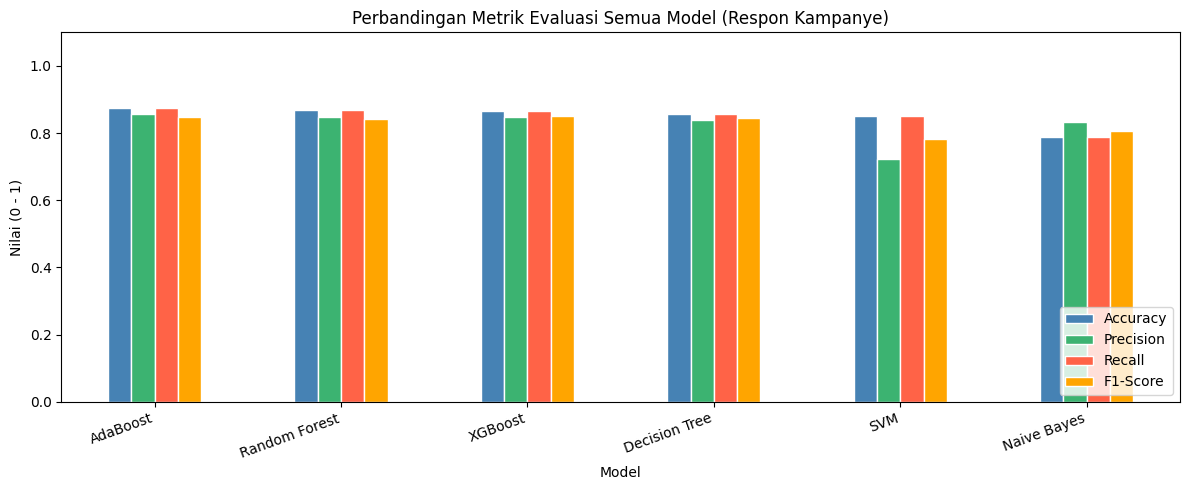


EVALUASI 2 — Accuracy Per Model


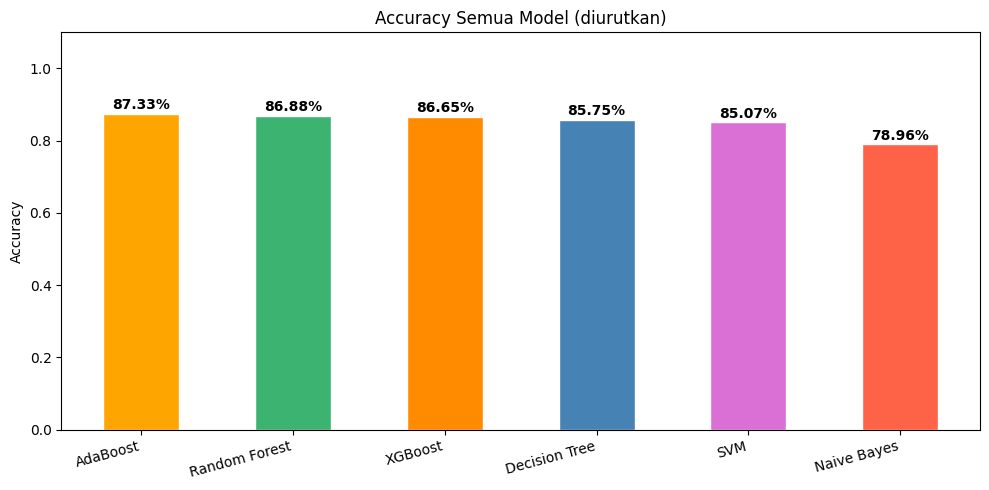

  AdaBoost             : 87.33%
  Random Forest        : 86.88%
  XGBoost              : 86.65%
  Decision Tree        : 85.75%
  SVM                  : 85.07%
  Naive Bayes          : 78.96%

EVALUASI 3 — Confusion Matrix
(Baris = kelas asli, Kolom = kelas prediksi)
(Nilai diagonal = prediksi BENAR)


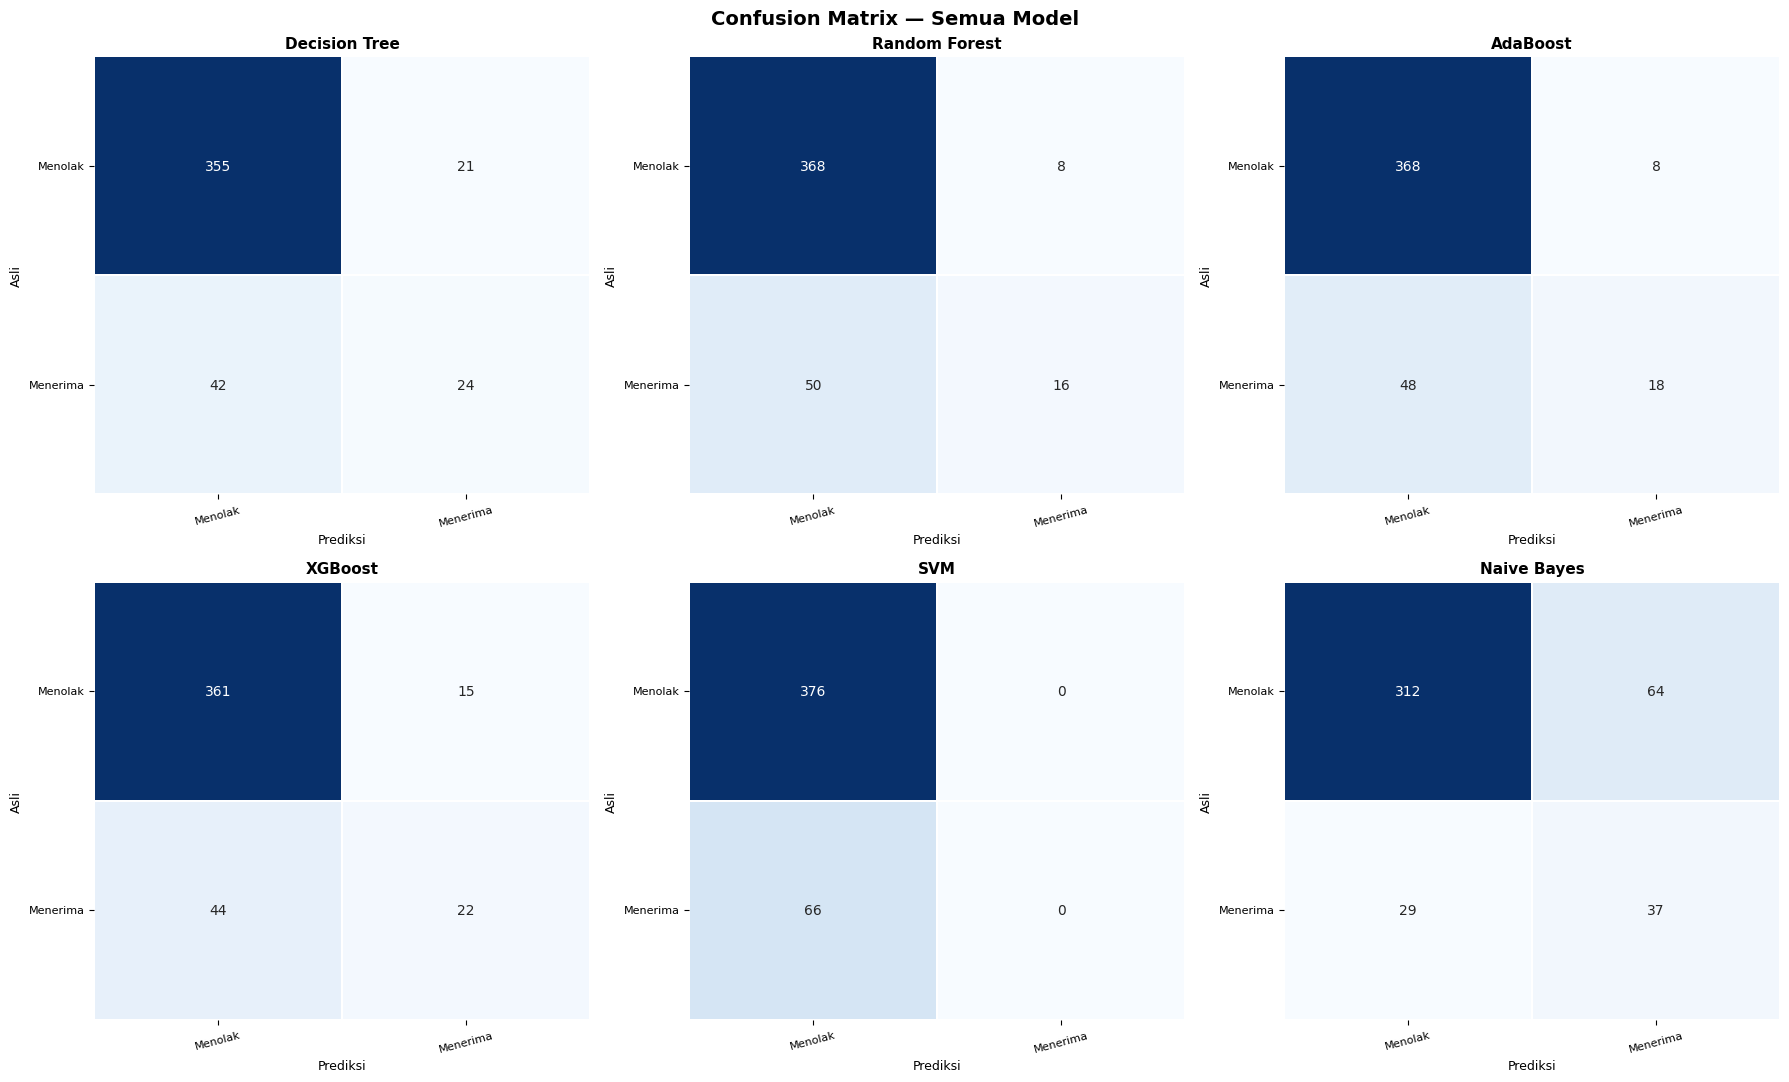


EVALUASI 4 — Classification Report Per Model
(Precision, Recall, F1-Score per kelas respon)

──────────────────────────────────────────────────
  Decision Tree
──────────────────────────────────────────────────
              precision    recall  f1-score   support

     Menolak       0.89      0.94      0.92       376
    Menerima       0.53      0.36      0.43        66

    accuracy                           0.86       442
   macro avg       0.71      0.65      0.68       442
weighted avg       0.84      0.86      0.85       442


──────────────────────────────────────────────────
  Random Forest
──────────────────────────────────────────────────
              precision    recall  f1-score   support

     Menolak       0.88      0.98      0.93       376
    Menerima       0.67      0.24      0.36        66

    accuracy                           0.87       442
   macro avg       0.77      0.61      0.64       442
weighted avg       0.85      0.87      0.84       442


──────────────

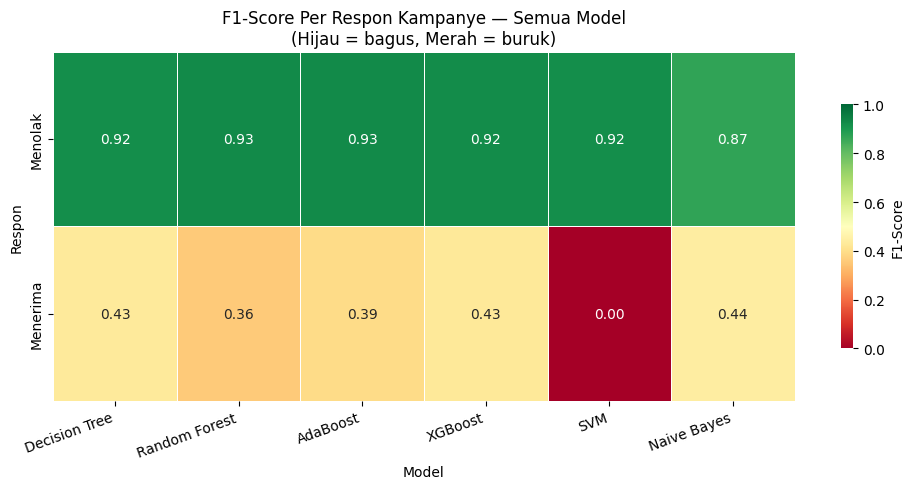


EVALUASI 6 — Cross Validation (5-Fold)
  Decision Tree        : [0.8529 0.8801 0.8529 0.8594 0.8367]  |  Mean=0.8564  Std=±0.0140
  Random Forest        : [0.8801 0.8982 0.862  0.8707 0.8821]  |  Mean=0.8786  Std=±0.0121
  AdaBoost             : [0.871  0.8869 0.8914 0.8798 0.8866]  |  Mean=0.8832  Std=±0.0071
  XGBoost              : [0.8756 0.8937 0.8688 0.8866 0.8889]  |  Mean=0.8827  Std=±0.0092
  SVM                  : [0.8484 0.8507 0.8507 0.8503 0.8503]  |  Mean=0.8501  Std=±0.0009
  Naive Bayes          : [0.7896 0.7828 0.7805 0.7868 0.7868]  |  Mean=0.7853  Std=±0.0032


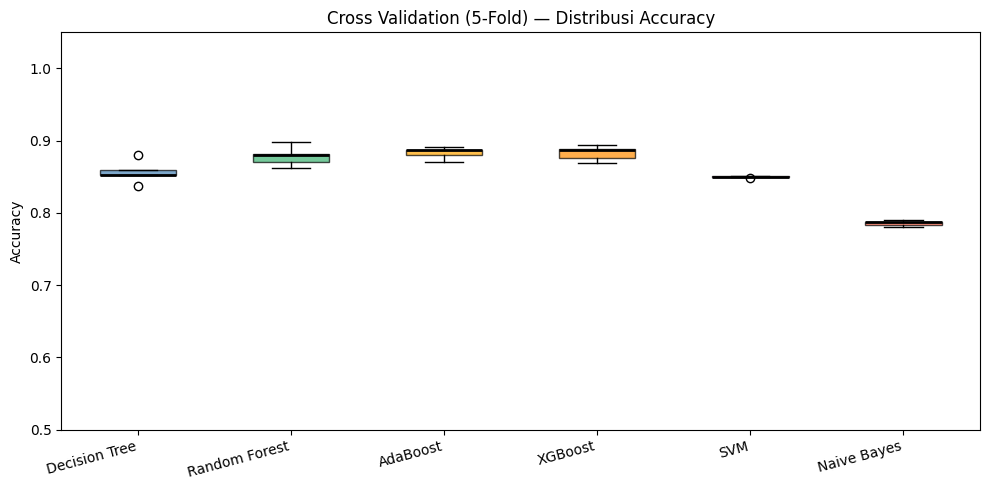


EVALUASI 7 — Radar Chart Perbandingan Model


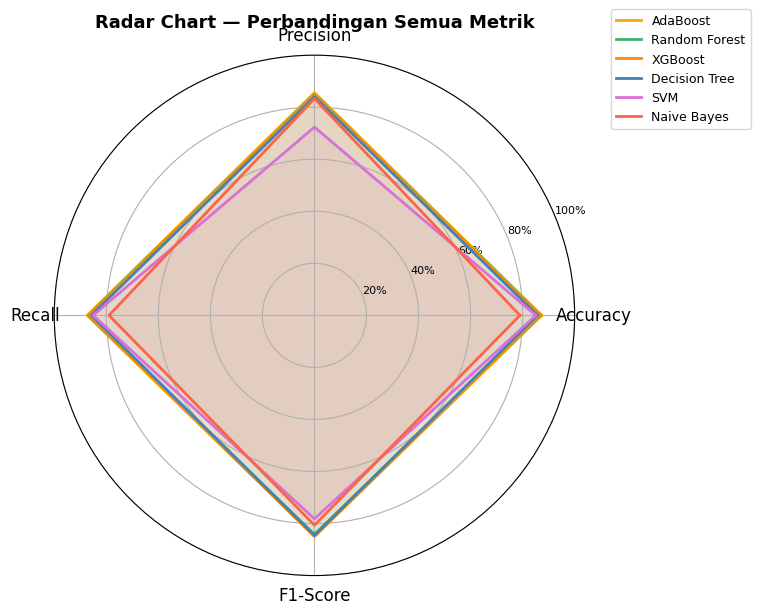


RINGKASAN AKHIR

Peringkat model berdasarkan Accuracy:
  1. AdaBoost             | Acc=0.8733 | F1=0.8490
  2. Random Forest        | Acc=0.8688 | F1=0.8416
  3. XGBoost              | Acc=0.8665 | F1=0.8502
  4. Decision Tree        | Acc=0.8575 | F1=0.8459
  5. SVM                  | Acc=0.8507 | F1=0.7820
  6. Naive Bayes          | Acc=0.7896 | F1=0.8065

🏆 Model terbaik : AdaBoost
   Accuracy      : 87.33%
   F1-Score      : 84.90%

Semua file evaluasi tersimpan!


In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)


target_classes = ['Menolak', 'Menerima']


X_scaled = X_train.copy()

print("Data siap!")
print(f"Training : {X_train.shape[0]} baris")
print(f"Testing  : {X_test.shape[0]} baris")


model_dict = {
    "Decision Tree" : dt,
    "Random Forest" : rf,
    "AdaBoost"      : ada,
    "XGBoost"       : xgb,
    "SVM"           : svm,
    "Naive Bayes"   : nb,
}

hasil_prediksi = {
    "Decision Tree" : pred_dt,
    "Random Forest" : pred_rf,
    "AdaBoost"      : pred_ada,
    "XGBoost"       : pred_xgb,
    "SVM"           : pred_svm,
    "Naive Bayes"   : pred_nb,
}


def hitung_metrik(y_asli, y_pred, nama_model):
    acc  = accuracy_score(y_asli, y_pred)
    prec = precision_score(y_asli, y_pred, average="weighted", zero_division=0)
    rec  = recall_score(y_asli, y_pred, average="weighted", zero_division=0)
    f1   = f1_score(y_asli, y_pred, average="weighted", zero_division=0)
    return {"Model": nama_model, "Accuracy": acc, "Precision": prec,
            "Recall": rec, "F1-Score": f1}


# TABEL PERBANDINGAN SEMUA METRIK
print("\n" + "=" * 55)
print("EVALUASI 1 — Tabel Perbandingan Semua Metrik")
print("=" * 55)

semua_hasil = []
for nama, pred in hasil_prediksi.items():
    semua_hasil.append(hitung_metrik(y_test, pred, nama))

df_hasil = pd.DataFrame(semua_hasil).set_index("Model")
df_hasil = df_hasil.sort_values("Accuracy", ascending=False)

print(df_hasil.round(4).to_string())

# Visualisasi tabel metrik sebagai bar chart
df_hasil.plot(kind="bar", figsize=(12, 5), edgecolor="white",
              color=["steelblue", "mediumseagreen", "tomato", "orange"])
plt.title("Perbandingan Metrik Evaluasi Semua Model (Respon Kampanye)")
plt.ylabel("Nilai (0 - 1)")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("eval1_perbandingan_metrik.png")
plt.show()


# EVALUASI 2 — ACCURACY PER MODEL (Bar Chart)
print("\n" + "=" * 55)
print("EVALUASI 2 — Accuracy Per Model")
print("=" * 55)

warna_model = {
    "Decision Tree" : "steelblue",
    "Random Forest" : "mediumseagreen",
    "AdaBoost"      : "orange",
    "XGBoost"       : "darkorange",
    "SVM"           : "orchid",
    "Naive Bayes"   : "tomato",
}

akurasi = {nama: accuracy_score(y_test, pred)
           for nama, pred in hasil_prediksi.items()}
akurasi_sorted = dict(sorted(akurasi.items(), key=lambda x: x[1], reverse=True))

plt.figure(figsize=(10, 5))
bars = plt.bar(akurasi_sorted.keys(), akurasi_sorted.values(),
               color=[warna_model[m] for m in akurasi_sorted],
               edgecolor="white", width=0.5)

for bar, val in zip(bars, akurasi_sorted.values()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f"{val*100:.2f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.title("Accuracy Semua Model (diurutkan)")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("eval2_accuracy.png")
plt.show()

for nama, acc in akurasi_sorted.items():
    print(f"  {nama:<20} : {acc*100:.2f}%")


# EVALUASI 3 — CONFUSION MATRIX SEMUA MODEL

print("\n" + "=" * 55)
print("EVALUASI 3 — Confusion Matrix")
print("=" * 55)
print("(Baris = kelas asli, Kolom = kelas prediksi)")
print("(Nilai diagonal = prediksi BENAR)")

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, (nama, pred) in enumerate(hasil_prediksi.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, ax=axes[i], annot=True, fmt="d", cmap="Blues",
                xticklabels=target_classes, yticklabels=target_classes,
                linewidths=0.3, cbar=False)
    axes[i].set_title(f"{nama}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Prediksi", fontsize=9)
    axes[i].set_ylabel("Asli", fontsize=9)
    axes[i].tick_params(axis="x", rotation=15, labelsize=8)
    axes[i].tick_params(axis="y", rotation=0, labelsize=8)

fig.suptitle("Confusion Matrix — Semua Model", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("eval3_confusion_matrix.png", dpi=120)
plt.show()


# EVALUASI 4 — CLASSIFICATION REPORT

print("\n" + "=" * 55)
print("EVALUASI 4 — Classification Report Per Model")
print("=" * 55)
print("(Precision, Recall, F1-Score per kelas respon)")

for nama, pred in hasil_prediksi.items():
    print(f"\n{'─'*50}")
    print(f"  {nama}")
    print(f"{'─'*50}")
    report = classification_report(y_test, pred,
                                   target_names=target_classes,
                                   zero_division=0)
    print(report)


# EVALUASI 5 — F1-SCORE PER KELAS (Heatmap)

print("\n" + "=" * 55)
print("EVALUASI 5 — F1-Score Per Kelas")
print("=" * 55)

df_f1 = pd.DataFrame(index=target_classes)

for nama, pred in hasil_prediksi.items():
    f1_kelas = f1_score(y_test, pred, average=None, zero_division=0)
    df_f1[nama] = f1_kelas

plt.figure(figsize=(10, 5))
sns.heatmap(df_f1, annot=True, fmt=".2f", cmap="RdYlGn",
            vmin=0, vmax=1, linewidths=0.4,
            cbar_kws={"shrink": 0.7, "label": "F1-Score"})
plt.title("F1-Score Per Respon Kampanye — Semua Model\n(Hijau = bagus, Merah = buruk)")
plt.xlabel("Model")
plt.ylabel("Respon")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("eval5_f1_per_kelas.png", dpi=120)
plt.show()


# EVALUASI 6 — CROSS VALIDATION (5-Fold)

print("\n" + "=" * 55)
print("EVALUASI 6 — Cross Validation (5-Fold)")
print("=" * 55)

hasil_cv = {}
for nama, model in model_dict.items():
    cv_scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")
    hasil_cv[nama] = cv_scores
    print(f"  {nama:<20} : {cv_scores.round(4)}  |  "
          f"Mean={cv_scores.mean():.4f}  Std=±{cv_scores.std():.4f}")

# Visualisasi cross validation — boxplot
plt.figure(figsize=(10, 5))
data_cv  = list(hasil_cv.values())
label_cv = list(hasil_cv.keys())
bp = plt.boxplot(data_cv, labels=label_cv, patch_artist=True,
                 medianprops=dict(color="black", linewidth=2))

for patch, nama in zip(bp["boxes"], label_cv):
    patch.set_facecolor(warna_model[nama])
    patch.set_alpha(0.7)

plt.title("Cross Validation (5-Fold) — Distribusi Accuracy")
plt.ylabel("Accuracy")
plt.xticks(rotation=15, ha="right")
plt.ylim(0.5, 1.05)
plt.tight_layout()
plt.savefig("eval6_cross_validation.png")
plt.show()


# EVALUASI 7 — RADAR CHART PERBANDINGAN MODEL

print("\n" + "=" * 55)
print("EVALUASI 7 — Radar Chart Perbandingan Model")
print("=" * 55)

metrik_nama  = ["Accuracy", "Precision", "Recall", "F1-Score"]
N            = len(metrik_nama)
angles       = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles      += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for nama, hasil in zip(df_hasil.index, df_hasil.values):
    nilai  = hasil.tolist()
    nilai += nilai[:1]
    ax.plot(angles, nilai, linewidth=2, label=nama, color=warna_model[nama])
    ax.fill(angles, nilai, alpha=0.08, color=warna_model[nama])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrik_nama, fontsize=12)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["20%","40%","60%","80%","100%"], fontsize=8)
ax.set_ylim(0, 1)
ax.set_title("Radar Chart — Perbandingan Semua Metrik",
             fontsize=13, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=9)
plt.tight_layout()
plt.savefig("eval7_radar_chart.png", dpi=120)
plt.show()


# RINGKASAN AKHIR — Model Terbaik

print("\n" + "=" * 55)
print("RINGKASAN AKHIR")
print("=" * 55)

print("\nPeringkat model berdasarkan Accuracy:")
for rank, (nama, row) in enumerate(df_hasil.iterrows(), 1):
    print(f"  {rank}. {nama:<20} | Acc={row['Accuracy']:.4f} | "
          f"F1={row['F1-Score']:.4f}")

model_terbaik = df_hasil["Accuracy"].idxmax()
print(f"\n🏆 Model terbaik : {model_terbaik}")
print(f"   Accuracy      : {df_hasil.loc[model_terbaik, 'Accuracy']*100:.2f}%")
print(f"   F1-Score      : {df_hasil.loc[model_terbaik, 'F1-Score']*100:.2f}%")
print("\nSemua file evaluasi tersimpan!")